# Forecast Model Equation Comparison

## Imports

In [865]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from odym import dynamic_stock_model as dsm
from scipy import stats
from scipy.interpolate import interp1d
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from scipy.optimize import curve_fit
import weibull
import math
from scipy.stats import linregress 
import matplotlib.lines as mlines
import matplotlib.ticker as mtick
from matplotlib.ticker import PercentFormatter
import plotly.graph_objects as go
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


## Read in Data

In [866]:
df_population = pd.read_csv(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\input_data_population.csv", index_col=0)
df_gdp = pd.read_csv(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\input_data_GDP.csv", index_col=0)
df_gdp_SSP2 = pd.read_excel(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\Jay MFA Code\Bldg_Stock-master\InputData\Pop_Data.xlsx', sheet_name='GDP_pc', index_col=0)
df_steel = pd.read_csv(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\input_data_production.csv', index_col=0)
df_recycling = pd.read_csv(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\input_data_recycling.csv", index_col=0)
df_energy_use = pd.read_excel(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\final_energy_use.xlsx", index_col=0)
df_urban = pd.read_excel(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\urban_population.xlsx", index_col=0)

## Clean and Prep Data

In [867]:
## Get GDP df
df_gdp.index = df_gdp.index.astype(int)  # ensure index is numeric
df_gdp = df_gdp.sort_index()
df_gdp = df_gdp.reindex(
    range(df_gdp.index.min(), df_gdp.index.max() + 1)
)

cols = ['gdp_ssp1','gdp_ssp2','gdp_ssp3','gdp_ssp4','gdp_ssp5']

df_gdp[cols] = (
    df_gdp[cols]
      .apply(pd.to_numeric, errors='coerce')
      .interpolate(method='cubic')
)

df_gdp= df_gdp.loc[df_gdp.index >= 1931]

In [868]:
## Get pop DF
df_population.index = df_population.index.astype(int)  # ensure index is numeric
df_population = df_population.sort_index()
df_population = df_population.reindex(
    range(1931, 2100+1)
)

cols = ['pop_ssp1','pop_ssp2','pop_ssp3','pop_ssp4','pop_ssp5']

df_population[cols] = (
    df_population[cols]
      .interpolate(method='cubic')
)


In [ ]:
## Get energy DF
df_energy_use.index = df_energy_use.index.astype(int)  # ensure index is numeric
df_energy_use = df_energy_use.sort_index()
df_energy_use = df_energy_use.reindex(
    range(1931, 2100+1)
)

cols = ['energy usage']

df_energy_use[cols] = (
    df_energy_use[cols]
      .interpolate(method='linear', limit_area='inside')
)

In [942]:
df_gdp

,gdp_ssp1,gdp_ssp2,gdp_ssp3,gdp_ssp4,gdp_ssp5,Source
1931,9931.000000,9931.000000,9931.000000,9931.000000,9931.000000,Maddison Project
1932,8381.000000,8381.000000,8381.000000,8381.000000,8381.000000,Maddison Project
1933,8048.000000,8048.000000,8048.000000,8048.000000,8048.000000,Maddison Project
1934,8667.000000,8667.000000,8667.000000,8667.000000,8667.000000,Maddison Project
1935,9681.000000,9681.000000,9681.000000,9681.000000,9681.000000,Maddison Project
...,...,...,...,...,...,...
2096,135685.626691,119845.660276,84960.532000,127108.928937,201666.721758,NaN
2097,136756.375509,120715.274883,85077.573401,127926.765039,204802.294777,NaN
2098,137831.680982,121587.065352,85193.064801,128745.280673,207979.129917,NaN
2099,138911.217636,122460.443214,85306.976801,129563.928205,211197.098038,NaN


In [870]:
df_energy_use.loc[2040:2060]

,energy usage
2040,90.340727
2041,90.471938
2042,90.603148
2043,90.734358
2044,90.865568
2045,90.996778
2046,91.127988
2047,91.259198
2048,91.390408
2049,91.521618


In [871]:
# ## Get urban DF
# df_urban.index = df_urban.index.astype(int)  # ensure index is numeric
# df_urban = df_urban.sort_index()
# df_urban = df_urban.reindex(
#     range(1931, 2100+1)
# )

# cols = ['urb_ssp1','urb_ssp2','urb_ssp3','urb_ssp4','urb_ssp5']

# df_urban[cols] = (
#     df_urban[cols]
#       .interpolate(method='cubic')
# )

In [872]:
df_population

,pop_ssp1,pop_ssp2,pop_ssp3,pop_ssp4,pop_ssp5,Source
1931,1.240396e+08,1.240396e+08,1.240396e+08,1.240396e+08,1.240396e+08,U.S. Censusu Bureau
1932,1.248405e+08,1.248405e+08,1.248405e+08,1.248405e+08,1.248405e+08,U.S. Censusu Bureau
1933,1.255788e+08,1.255788e+08,1.255788e+08,1.255788e+08,1.255788e+08,U.S. Censusu Bureau
1934,1.263738e+08,1.263738e+08,1.263738e+08,1.263738e+08,1.263738e+08,U.S. Censusu Bureau
1935,1.272502e+08,1.272502e+08,1.272502e+08,1.272502e+08,1.272502e+08,U.S. Censusu Bureau
...,...,...,...,...,...,...
2096,3.852488e+08,4.062801e+08,4.514007e+08,3.234784e+08,4.472286e+08,NaN
2097,3.841043e+08,4.061230e+08,4.535483e+08,3.215325e+08,4.462173e+08,NaN
2098,3.828507e+08,4.059405e+08,4.557263e+08,3.195466e+08,4.450611e+08,NaN
2099,3.814823e+08,4.057335e+08,4.579347e+08,3.175217e+08,4.437532e+08,NaN


In [943]:
df_steel

,total-production,structural-total
1931,23536.93607,2396.48
1932,12411.20919,1263.68
1933,21075.74094,2145.89
1934,23636.72651,2406.64
1935,30928.68612,3149.10
...,...,...
2019,87300.00000,8888.71
2020,73500.00000,7483.62
2021,85900.00000,8746.17
2022,81200.00000,8267.62


In [873]:
# Wrap result back into a DataFrame with clean column names
df_total_gdp = pd.DataFrame(
    df_gdp.iloc[:,:5].values * df_population.iloc[:,:5].values,
    index=df_gdp.index,
    columns=[f"total_gdp_ssp{i}" for i in range(1, 6)]
)

In [874]:
df_steel['structural-total'].to_csv(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\input_data\steel_input_data")
df_population.to_csv(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\input_data\pop_input_data")
df_gdp.to_csv(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\input_data\gdp_input_data")
df_energy_use.to_csv(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\input_data\energy_input_data")

In [944]:
for name, df in [('df_population', df_population), 
                 ('df_gdp', df_gdp), 
                 ('df_energy_use', df_energy_use),
                 ('df_steel', df_steel)]:
    print(f"\n=== {name} ===")
    print(f"Index: {df.index.min()} to {df.index.max()}")
    print(f"Columns: {df.columns.tolist()}")
    print(df.head(3))


=== df_population ===
Index: 1931 to 2100
Columns: ['pop_ssp1', 'pop_ssp2', 'pop_ssp3', 'pop_ssp4', 'pop_ssp5', 'Source']
         pop_ssp1     pop_ssp2     pop_ssp3     pop_ssp4     pop_ssp5  \
1931  124039648.0  124039648.0  124039648.0  124039648.0  124039648.0   
1932  124840471.0  124840471.0  124840471.0  124840471.0  124840471.0   
1933  125578763.0  125578763.0  125578763.0  125578763.0  125578763.0   

                   Source  
1931  U.S. Censusu Bureau  
1932  U.S. Censusu Bureau  
1933  U.S. Censusu Bureau  

=== df_gdp ===
Index: 1931 to 2100
Columns: ['gdp_ssp1', 'gdp_ssp2', 'gdp_ssp3', 'gdp_ssp4', 'gdp_ssp5', 'Source']
      gdp_ssp1  gdp_ssp2  gdp_ssp3  gdp_ssp4  gdp_ssp5            Source
1931    9931.0    9931.0    9931.0    9931.0    9931.0  Maddison Project
1932    8381.0    8381.0    8381.0    8381.0    8381.0  Maddison Project
1933    8048.0    8048.0    8048.0    8048.0    8048.0  Maddison Project

=== df_energy_use ===
Index: 1931 to 2100
Columns: ['energy usa

In [876]:
df_total_gdp

,total_gdp_ssp1,total_gdp_ssp2,total_gdp_ssp3,total_gdp_ssp4,total_gdp_ssp5
1931,1.231838e+12,1.231838e+12,1.231838e+12,1.231838e+12,1.231838e+12
1932,1.046288e+12,1.046288e+12,1.046288e+12,1.046288e+12,1.046288e+12
1933,1.010658e+12,1.010658e+12,1.010658e+12,1.010658e+12,1.010658e+12
1934,1.095281e+12,1.095281e+12,1.095281e+12,1.095281e+12,1.095281e+12
1935,1.231909e+12,1.231909e+12,1.231909e+12,1.231909e+12,1.231909e+12
...,...,...,...,...,...
2096,5.227273e+13,4.869091e+13,3.835124e+13,4.111699e+13,9.019112e+13
2097,5.252871e+13,4.902525e+13,3.858679e+13,4.113261e+13,9.138633e+13
2098,5.276896e+13,4.935712e+13,3.882472e+13,4.114011e+13,9.256342e+13
2099,5.299217e+13,4.968630e+13,3.906502e+13,4.113935e+13,9.371939e+13


# Get Elasticities of Variables 

For certain equations to develop a model, elasticities are necessary. This is the section in which that is accomplished.

In [931]:
df_elasticities = pd.concat([df_population['pop_ssp2'],df_gdp['gdp_ssp2'],df_energy_use['energy usage'],df_steel['structural-total']],axis = 1)
df_elasticities = df_elasticities.loc[1931:2023]

In [878]:
df_elasticities 

,pop_ssp2,total_gdp_ssp2,energy usage,total-production,structural-total
1931,124039648.0,1.231838e+12,23.680000,23536.93607,2396.48
1932,124840471.0,1.046288e+12,22.869000,12411.20919,1263.68
1933,125578763.0,1.010658e+12,22.058000,21075.74094,2145.89
1934,126373773.0,1.095281e+12,21.247000,23636.72651,2406.64
1935,127250232.0,1.231909e+12,20.436000,30928.68612,3149.10
...,...,...,...,...,...
2019,330226227.0,1.891150e+13,96.595282,87300.00000,8888.71
2020,331515736.0,1.969070e+13,88.870945,73500.00000,7483.62
2021,332099760.0,2.031797e+13,93.363948,85900.00000,8746.17
2022,333288000.0,2.086255e+13,92.382874,81200.00000,8267.62


In [879]:
# fig, axes = plt.subplots(nrows = 2, ncols = 2, figsize=(14,5), constrained_layout = True)
# axes = axes.flatten()

# xcols = ['pop_ssp2', 'gdp_ssp2', 'energy_usage']

# for xcol, ax in zip(xcols, axes):
#     x = np.log(df_elasticities[xcol].loc[1931:2023])
#     y = np.log(df_elasticities['total-production'].loc[1931:2023])
#     ax.scatter(x,y, alpha = 0.6, s = 30, color = 'tab:blue', edgecolor = 'none')

#     mask = np.isfinite(x) & np.isfinite(y)
#     if mask.sum() > 1:
#         slope, intercept, r_value, p_value, std_err = linregress(x[mask], y[mask])

#         # slope = elasticity
#         X_sorted = np.sort(x[mask])
#         ax.plot(X_sorted, intercept + slope*X_sorted, 
#                 color='red', lw=2, 
#                 label=f"Elasticity = {slope:.3f}")
#     ax.set_xlabel(xcol,fontsize = 9)
#     ax.set_ylabel('Total Steel (tons)')
#     ax.grid(True, linestyle = '--', alpha = 0.3)
#     ax.legend(loc = 'upper left')

# for ax in axes[len(xcols):]:
#     ax.set_visible(False)

# fig.suptitle('Elastacitites with respect to Strucutural Steel', fontsize = 14, fontweight = 'bold')
# plt.show()

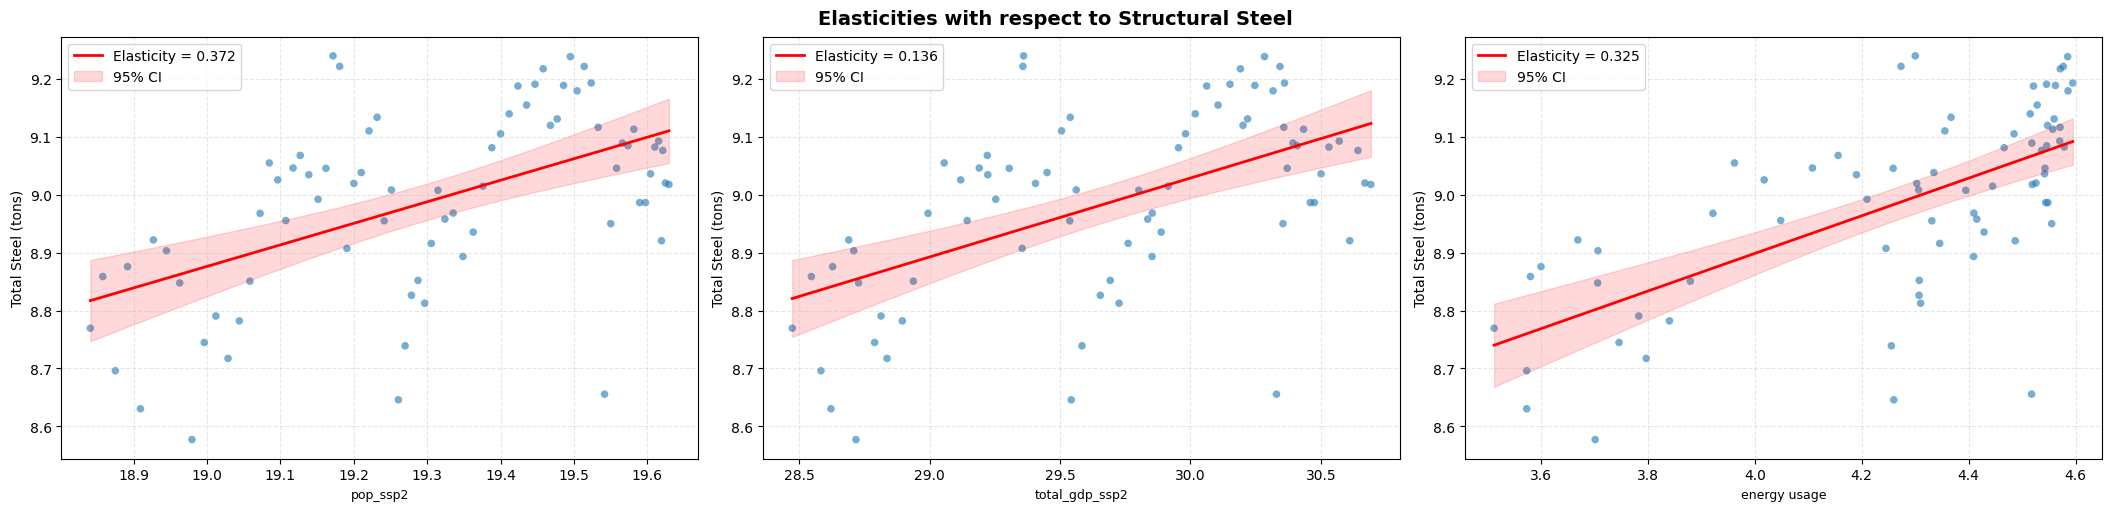

In [920]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(21, 5), constrained_layout=True)
axes = axes.flatten()

xcols = ['pop_ssp2', 'total_gdp_ssp2', 'energy usage']

for xcol, ax in zip(xcols, axes):
    x = np.log(df_elasticities[xcol].loc[1950:2023])
    y = np.log(df_elasticities['structural-total'].loc[1950:2023])
    ax.scatter(x, y, alpha=0.6, s=30, color='tab:blue', edgecolor='none')

    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() > 1:
        x_clean = x[mask].values
        y_clean = y[mask].values

        slope, intercept, r_value, p_value, std_err = linregress(x_clean, y_clean)

        X_sorted = np.sort(x_clean)
        y_pred = intercept + slope * X_sorted

        # Confidence interval
        n = len(x_clean)
        x_mean = np.mean(x_clean)
        se = np.sqrt(
            np.sum((y_clean - (intercept + slope * x_clean)) ** 2) / (n - 2)
        )
        t_crit = stats.t.ppf(0.975, df=n - 2)
        ci = t_crit * se * np.sqrt(1/n + (X_sorted - x_mean)**2 / np.sum((x_clean - x_mean)**2))

        ax.plot(X_sorted, y_pred, color='red', lw=2, label=f"Elasticity = {slope:.3f}")
        ax.fill_between(X_sorted, y_pred - ci, y_pred + ci,
                        color='red', alpha=0.15, label="95% CI")

    ax.set_xlabel(xcol, fontsize=9)
    ax.set_ylabel('Total Steel (tons)')
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.legend(loc='upper left')

for ax in axes[len(xcols):]:
    ax.set_visible(False)

fig.suptitle('Elasticities with respect to Structural Steel', fontsize=14, fontweight='bold')
plt.show()

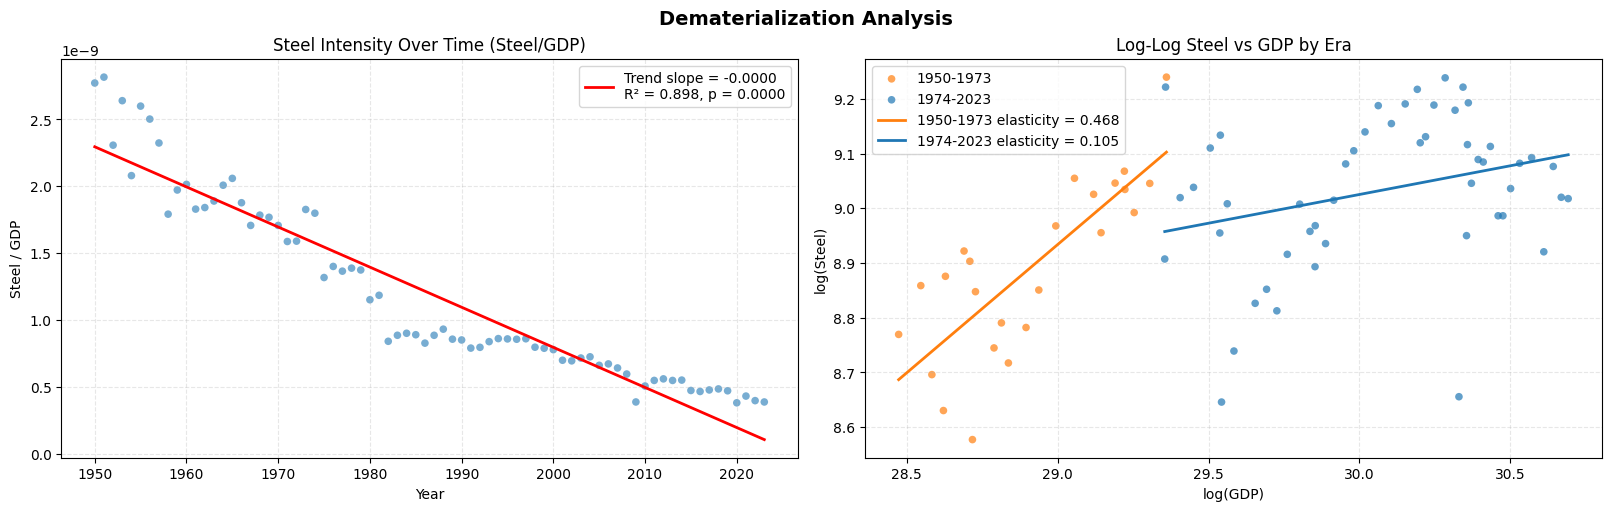


Intensity trend: -0.000000 per year
Total intensity change 1950-2023: -0.0000 (-79.0%)
p-value: 0.0000 (significant)


In [923]:
#Here's the code to plot steel intensity (steel/GDP) over time and check for dematerialization:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Calculate steel intensity
df_intensity = df_elasticities.loc[1950:2023].copy()
df_intensity['steel_intensity'] = df_intensity['structural-total'] / df_intensity['total_gdp_ssp2']

# Fit a linear trend to intensity over time
years = df_intensity.index.values
intensity = df_intensity['steel_intensity'].values

mask = np.isfinite(years) & np.isfinite(intensity)
slope, intercept, r_value, p_value, std_err = linregress(years[mask], intensity[mask])

# --- Plot ---
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 5), constrained_layout=True)

# Left: Steel intensity over time
ax = axes[0]
ax.scatter(years, intensity, alpha=0.6, s=30, color='tab:blue', edgecolor='none')
ax.plot(years[mask], intercept + slope * years[mask], color='red', lw=2,
        label=f"Trend slope = {slope:.4f}\nR² = {r_value**2:.3f}, p = {p_value:.4f}")
ax.set_xlabel('Year')
ax.set_ylabel('Steel / GDP')
ax.set_title('Steel Intensity Over Time (Steel/GDP)')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.3)

# Right: Log steel vs log GDP colored by era to visualize the break
ax = axes[1]
break_year = 1973  # suspected structural break

pre = df_intensity.loc[:break_year]
post = df_intensity.loc[break_year+1:]

ax.scatter(np.log(pre['total_gdp_ssp2']), np.log(pre['structural-total']),
           alpha=0.7, s=30, color='tab:orange', edgecolor='none', label=f'1950-{break_year}')
ax.scatter(np.log(post['total_gdp_ssp2']), np.log(post['structural-total']),
           alpha=0.7, s=30, color='tab:blue', edgecolor='none', label=f'{break_year+1}-2023')

# Fit separate elasticities for each era
for subset, color, label in [
    (pre, 'tab:orange', f'1950-{break_year}'),
    (post, 'tab:blue', f'{break_year+1}-2023')
]:
    x = np.log(subset['total_gdp_ssp2'].values)
    y = np.log(subset['structural-total'].values)
    mask2 = np.isfinite(x) & np.isfinite(y)
    if mask2.sum() > 1:
        s, i, r, p, _ = linregress(x[mask2], y[mask2])
        x_sorted = np.sort(x[mask2])
        ax.plot(x_sorted, i + s * x_sorted, color=color, lw=2,
                label=f'{label} elasticity = {s:.3f}')

ax.set_xlabel('log(GDP)')
ax.set_ylabel('log(Steel)')
ax.set_title('Log-Log Steel vs GDP by Era')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.3)

fig.suptitle('Dematerialization Analysis', fontsize=14, fontweight='bold')
plt.show()

print(f"\nIntensity trend: {slope:.6f} per year")
print(f"Total intensity change 1950-2023: {slope*73:.4f} ({slope*73/intensity[0]*100:.1f}%)")
print(f"p-value: {p_value:.4f} ({'significant' if p_value < 0.05 else 'not significant'})")

=== Intensity Trend ===
Intercept: 8.139987e+00
Slope:     -3.966416e-03 per year


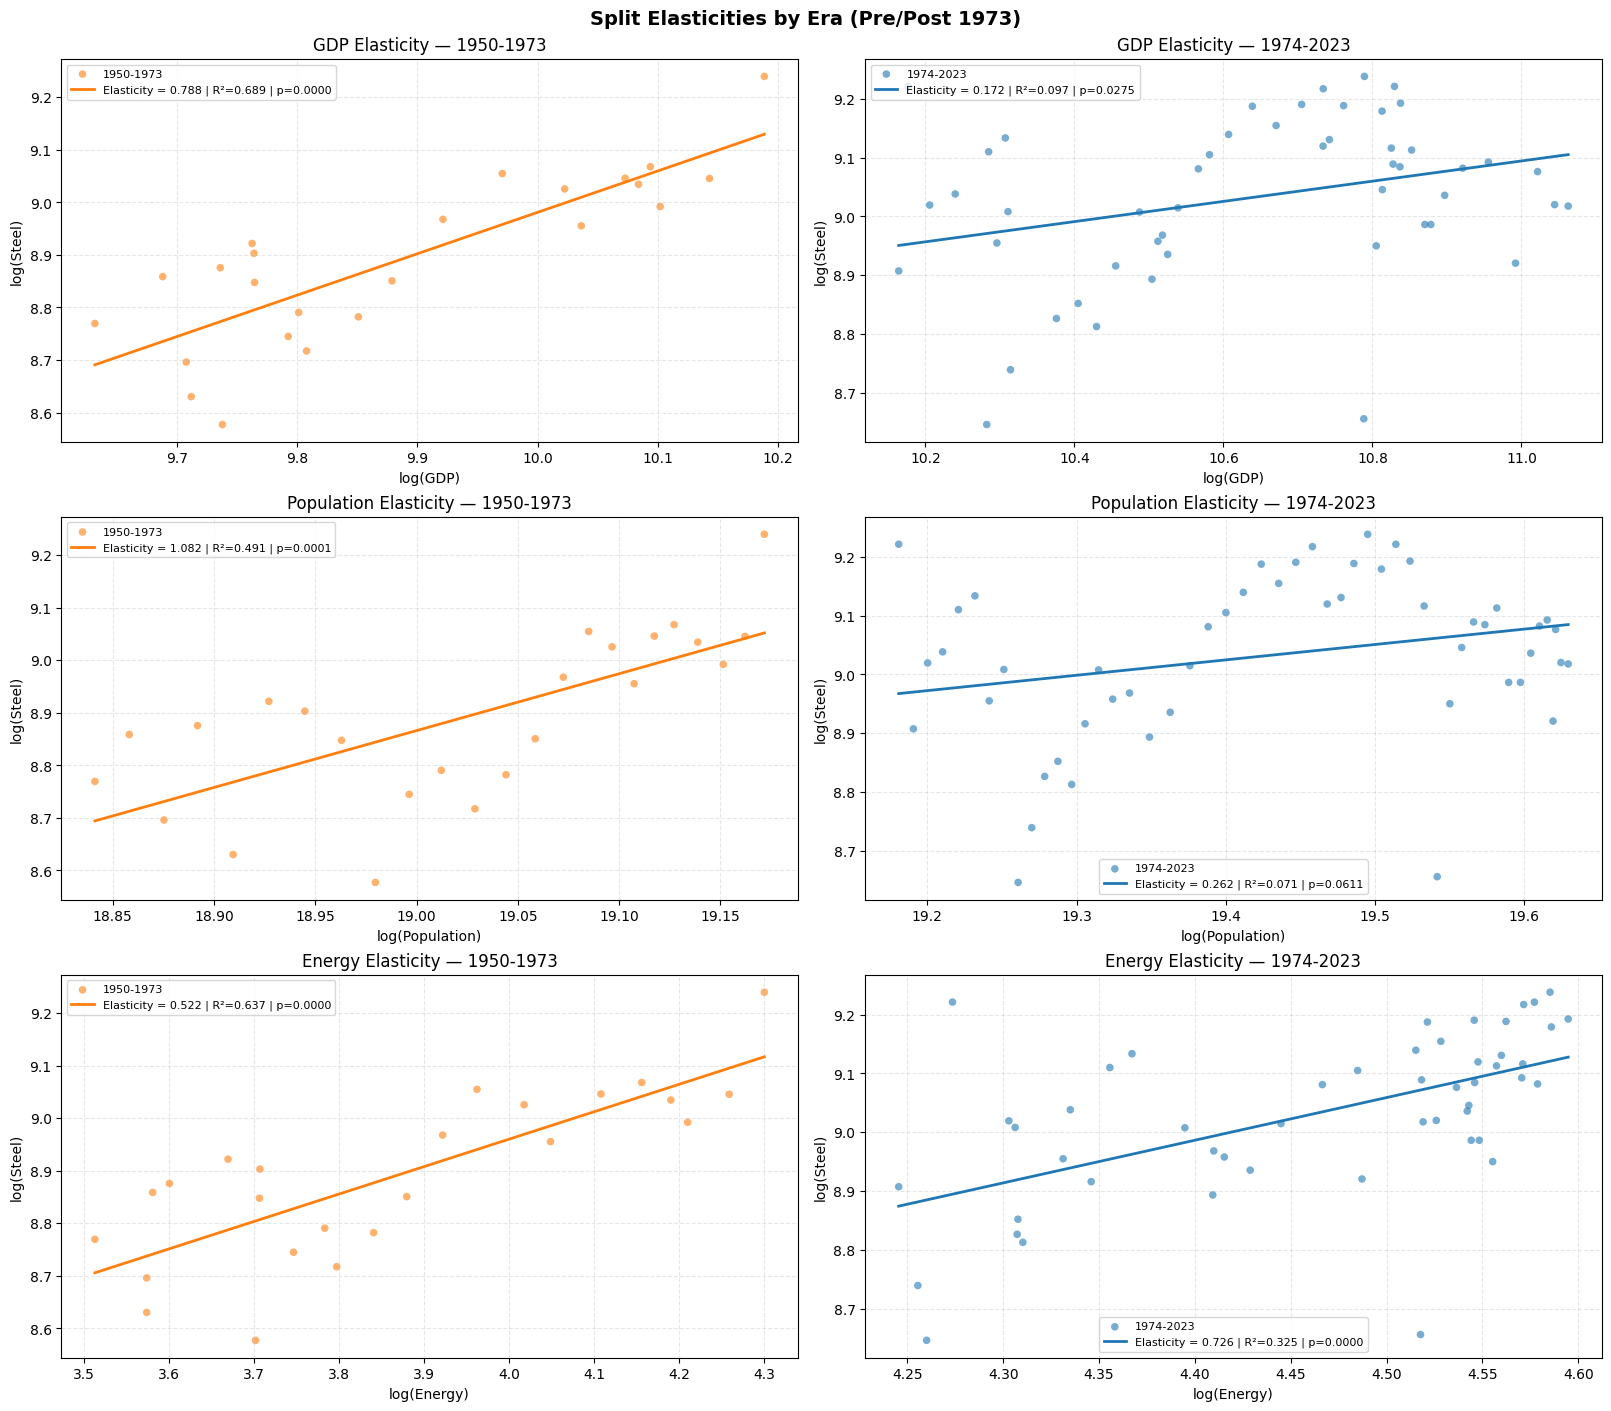


=== Split Elasticities Summary ===
Variable       Pre-1973  Post-1973
-----------------------------------
GDP               0.788      0.172
Population        1.082      0.262
Energy            0.522      0.726


In [932]:
# ── 1. Steel Intensity Trend ──────────────────────────────────────────────────
df_intensity = df_elasticities.loc[1950:2023].copy()
df_intensity['steel_intensity'] = df_intensity['structural-total'] / df_intensity['gdp_ssp2']

years = df_intensity.index.values
intensity = df_intensity['steel_intensity'].values
mask = np.isfinite(years) & np.isfinite(intensity)

intensity_slope, intensity_intercept, *_ = linregress(years[mask], intensity[mask])

print("=== Intensity Trend ===")
print(f"Intercept: {intensity_intercept:.6e}")
print(f"Slope:     {intensity_slope:.6e} per year")

# ── 2. Split Elasticities ─────────────────────────────────────────────────────
break_year = 1973
variables = {
    'GDP':        'gdp_ssp2',
    'Population': 'pop_ssp2',
    'Energy':     'energy usage',
}

elasticities = {}

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(16, 14), constrained_layout=True)

for i, (label, col) in enumerate(variables.items()):
    pre  = df_elasticities.loc[1950:break_year]
    post = df_elasticities.loc[break_year+1:2023]

    results = {}
    for era, subset, color, era_label in [
        ('pre',  pre,  'tab:orange', f'1950-{break_year}'),
        ('post', post, 'tab:blue',   f'{break_year+1}-2023'),
    ]:
        x = np.log(subset[col].values).astype(float)
        y = np.log(subset['structural-total'].values).astype(float)
        mask2 = np.isfinite(x) & np.isfinite(y)

        s, intercept, r, p, se = linregress(x[mask2], y[mask2])
        results[era] = {'slope': s, 'intercept': intercept, 'r2': r**2, 'p': p}

        # Scatter + fit line
        ax = axes[i][0] if era == 'pre' else axes[i][1]
        ax.scatter(x[mask2], y[mask2], alpha=0.6, s=30,
                   color=color, edgecolor='none', label=era_label)
        x_sorted = np.sort(x[mask2])
        ax.plot(x_sorted, intercept + s * x_sorted, color=color, lw=2,
                label=f'Elasticity = {s:.3f} | R²={r**2:.3f} | p={p:.4f}')
        ax.set_xlabel(f'log({label})')
        ax.set_ylabel('log(Steel)')
        ax.set_title(f'{label} Elasticity — {era_label}')
        ax.legend(fontsize=8)
        ax.grid(True, linestyle='--', alpha=0.3)

    elasticities[label] = results

fig.suptitle('Split Elasticities by Era (Pre/Post 1973)', fontsize=14, fontweight='bold')
plt.show()

# ── 3. Summary ────────────────────────────────────────────────────────────────
print("\n=== Split Elasticities Summary ===")
print(f"{'Variable':<12} {'Pre-1973':>10} {'Post-1973':>10}")
print("-" * 35)
for label, res in elasticities.items():
    print(f"{label:<12} {res['pre']['slope']:>10.3f} {res['post']['slope']:>10.3f}")

In [881]:
## Define elasticities

pop_elast = 0.902
gdp_elast = 0.337
energy_elast = 0.614
urb_elast = 2.595
stuctural_constant = .1*0.49

=== Unified Model Coefficients (No Population) ===
Base intercept:        -9.8963
Post-1973 intercept Δ: 16.4788

Variable     Pre-1973  Post-1973      Shift
------------------------------------------
GDP             2.316     -0.572     -2.887
Energy         -1.061      1.911      2.972

=== Hindcast Metrics ===
R²:   0.6886
RMSE: 687.4
MAPE: 6.50%
Bias: -31.4


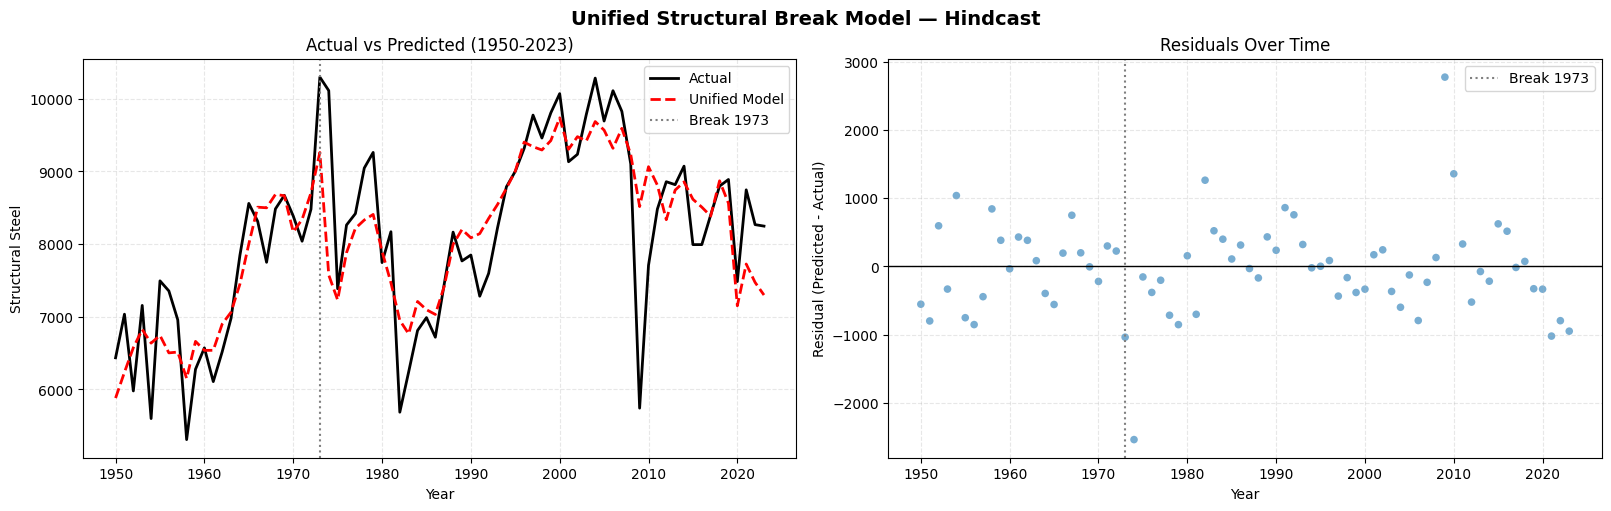

In [935]:
# ── 1. Build regression dataset ──────────────────────────────────────────────
df_model = df_elasticities.loc[1950:2023].copy()
df_model = df_model.dropna(subset=['structural-total', 'gdp_ssp2', 
                                    'pop_ssp2', 'energy usage'])

log_steel  = np.log(df_model['structural-total'].values)
log_gdp    = np.log(df_model['gdp_ssp2'].values)
log_pop    = np.log(df_model['pop_ssp2'].values)
log_energy = np.log(df_model['energy usage'].values)

# Binary era indicator (0=pre, 1=post)
post = (df_model.index > 1973).astype(float)
# ── 2. Build feature matrix WITHOUT population ────────────────────────────────
X = np.column_stack([
    log_gdp,
    log_energy,
    post * log_gdp,    # GDP elasticity shift post-1973
    post * log_energy, # Energy elasticity shift post-1973
    post,              # Intercept shift post-1973
])

X_const = np.column_stack([np.ones(len(X)), X])
coeffs, _, _, _ = lstsq(X_const, log_steel, rcond=None)

intercept       = coeffs[0]
gdp_e           = coeffs[1]
energy_e        = coeffs[2]
gdp_e_shift     = coeffs[3]
energy_e_shift  = coeffs[4]
intercept_shift = coeffs[5]

print("=== Unified Model Coefficients (No Population) ===")
print(f"Base intercept:        {intercept:.4f}")
print(f"Post-1973 intercept Δ: {intercept_shift:.4f}")
print(f"")
print(f"{'Variable':<10} {'Pre-1973':>10} {'Post-1973':>10} {'Shift':>10}")
print(f"{'-'*42}")
print(f"{'GDP':<10} {gdp_e:>10.3f} {gdp_e+gdp_e_shift:>10.3f} {gdp_e_shift:>10.3f}")
print(f"{'Energy':<10} {energy_e:>10.3f} {energy_e+energy_e_shift:>10.3f} {energy_e_shift:>10.3f}")
# ── 4. Predict ────────────────────────────────────────────────────────────────
log_steel_pred = X_const @ coeffs
steel_pred     = np.exp(log_steel_pred)

actual    = df_model['structural-total'].values
ss_res    = np.sum((actual - steel_pred) ** 2)
ss_tot    = np.sum((actual - np.mean(actual)) ** 2)
r2        = 1 - ss_res / ss_tot
rmse      = np.sqrt(np.mean((actual - steel_pred) ** 2))
mape      = np.mean(np.abs((actual - steel_pred) / actual)) * 100
bias      = np.mean(steel_pred - actual)

print(f"\n=== Hindcast Metrics ===")
print(f"R²:   {r2:.4f}")
print(f"RMSE: {rmse:.1f}")
print(f"MAPE: {mape:.2f}%")
print(f"Bias: {bias:.1f}")

# ── 5. Plot ───────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5), constrained_layout=True)

ax = axes[0]
ax.plot(df_model.index, actual,     color='black', lw=2, label='Actual')
ax.plot(df_model.index, steel_pred, color='red', lw=2,
        linestyle='--', label='Unified Model')
ax.axvline(1973, color='grey', linestyle=':', lw=1.5, label='Break 1973')
ax.set_xlabel('Year')
ax.set_ylabel('Structural Steel')
ax.set_title('Actual vs Predicted (1950-2023)')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.3)

ax = axes[1]
residuals = steel_pred - actual
ax.scatter(df_model.index, residuals, alpha=0.6, s=30,
           color='tab:blue', edgecolor='none')
ax.axhline(0,    color='black', lw=1)
ax.axvline(1973, color='grey',  linestyle=':', lw=1.5, label='Break 1973')
ax.set_xlabel('Year')
ax.set_ylabel('Residual (Predicted - Actual)')
ax.set_title('Residuals Over Time')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.3)

fig.suptitle('Unified Structural Break Model — Hindcast', fontsize=14, fontweight='bold')
plt.show()

=== Energy-Only Model Coefficients ===
Base intercept:        6.8737
Post-1973 intercept Δ: -1.0812

Variable     Pre-1973  Post-1973      Shift
------------------------------------------
Energy          0.522      0.726      0.204

=== Hindcast Metrics ===
R²:   0.5396
RMSE: 835.8
MAPE: 8.45%
Bias: -45.4


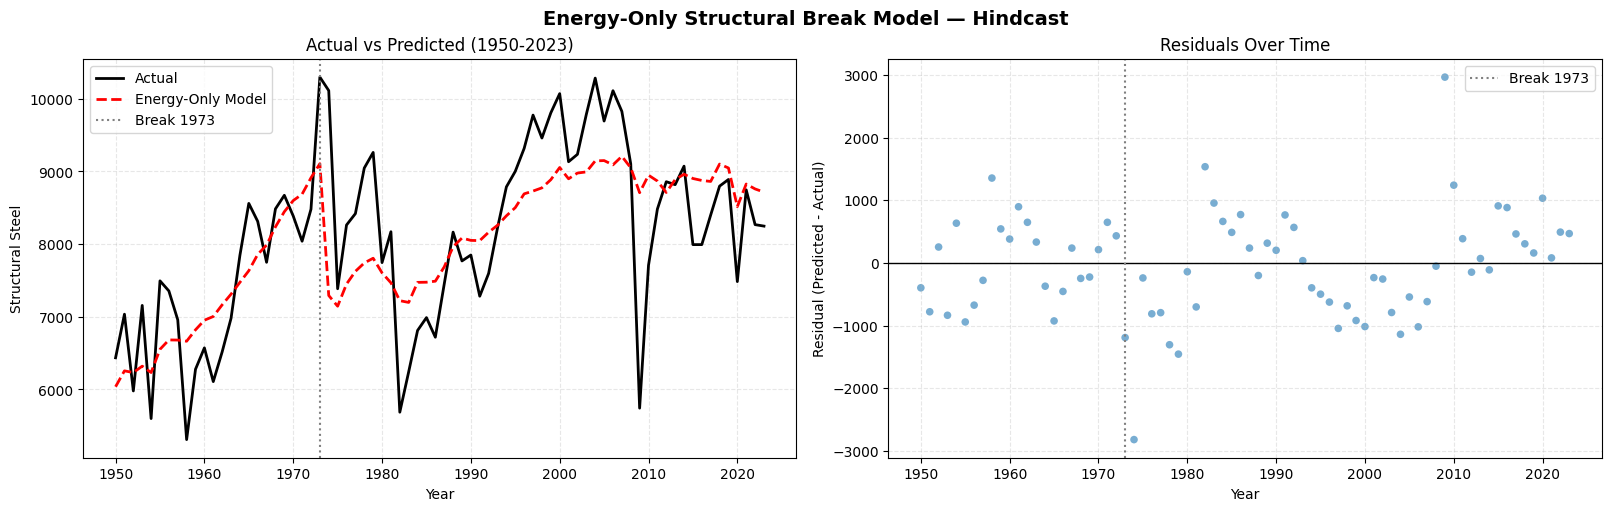

In [936]:
# ── 1. Build feature matrix ENERGY ONLY ──────────────────────────────────────
X = np.column_stack([
    log_energy,
    post * log_energy,  # elasticity shift post-1973
    post,               # intercept shift
])

X_const = np.column_stack([np.ones(len(X)), X])
coeffs, _, _, _ = lstsq(X_const, log_steel, rcond=None)

intercept       = coeffs[0]
energy_e        = coeffs[1]
energy_e_shift  = coeffs[2]
intercept_shift = coeffs[3]

print("=== Energy-Only Model Coefficients ===")
print(f"Base intercept:        {intercept:.4f}")
print(f"Post-1973 intercept Δ: {intercept_shift:.4f}")
print(f"")
print(f"{'Variable':<10} {'Pre-1973':>10} {'Post-1973':>10} {'Shift':>10}")
print(f"{'-'*42}")
print(f"{'Energy':<10} {energy_e:>10.3f} {energy_e+energy_e_shift:>10.3f} {energy_e_shift:>10.3f}")

# ── 2. Predict ────────────────────────────────────────────────────────────────
log_steel_pred = X_const @ coeffs
steel_pred     = np.exp(log_steel_pred)

actual = df_model['structural-total'].values
ss_res = np.sum((actual - steel_pred) ** 2)
ss_tot = np.sum((actual - np.mean(actual)) ** 2)
r2     = 1 - ss_res / ss_tot
rmse   = np.sqrt(np.mean((actual - steel_pred) ** 2))
mape   = np.mean(np.abs((actual - steel_pred) / actual)) * 100
bias   = np.mean(steel_pred - actual)

print(f"\n=== Hindcast Metrics ===")
print(f"R²:   {r2:.4f}")
print(f"RMSE: {rmse:.1f}")
print(f"MAPE: {mape:.2f}%")
print(f"Bias: {bias:.1f}")

# ── 3. Plot ───────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5), constrained_layout=True)

ax = axes[0]
ax.plot(df_model.index, actual,     color='black', lw=2, label='Actual')
ax.plot(df_model.index, steel_pred, color='red',   lw=2,
        linestyle='--', label='Energy-Only Model')
ax.axvline(1973, color='grey', linestyle=':', lw=1.5, label='Break 1973')
ax.set_xlabel('Year')
ax.set_ylabel('Structural Steel')
ax.set_title('Actual vs Predicted (1950-2023)')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.3)

ax = axes[1]
residuals = steel_pred - actual
ax.scatter(df_model.index, residuals, alpha=0.6, s=30,
           color='tab:blue', edgecolor='none')
ax.axhline(0,    color='black', lw=1)
ax.axvline(1973, color='grey',  linestyle=':', lw=1.5, label='Break 1973')
ax.set_xlabel('Year')
ax.set_ylabel('Residual (Predicted - Actual)')
ax.set_title('Residuals Over Time')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.3)

fig.suptitle('Energy-Only Structural Break Model — Hindcast', fontsize=14, fontweight='bold')
plt.show()

Optimal alpha: 0.1048

=== Ridge Model Coefficients (alpha=0.1048) ===
Base intercept:        7.7488
Post-1973 intercept Δ: -0.6107

Variable     Pre-1973  Post-1973      Shift
------------------------------------------
GDP            -0.170     -0.201     -0.031
Energy          0.730      0.904      0.174

=== Hindcast Metrics ===
R²:   0.5837
RMSE: 794.7
MAPE: 8.16%
Bias: -46.2


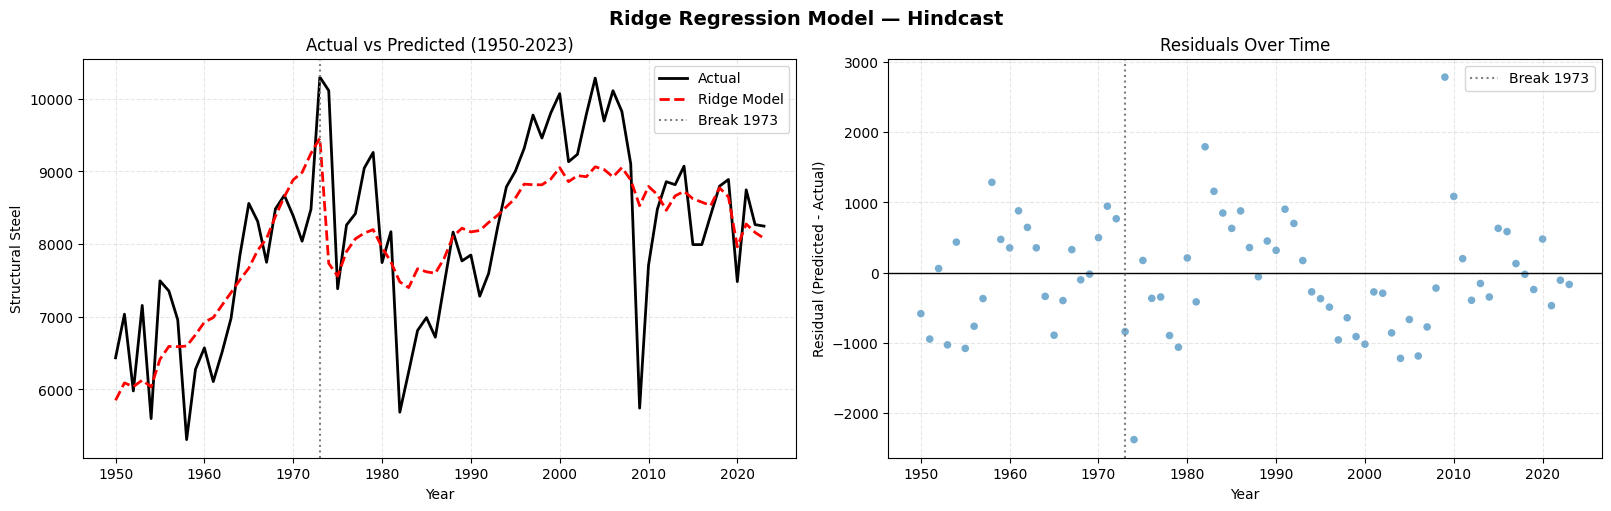

In [937]:
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.preprocessing import StandardScaler
import numpy as np
import matplotlib.pyplot as plt

# ── 1. Build full feature matrix (GDP + Energy, no population) ────────────────
X = np.column_stack([
    log_gdp,
    log_energy,
    post * log_gdp,
    post * log_energy,
    post,
])

# ── 2. Find optimal alpha via cross-validation ────────────────────────────────
alphas = np.logspace(-3, 5, 100)  # test wide range of regularization strengths

ridge_cv = RidgeCV(alphas=alphas, scoring='r2', cv=5)
ridge_cv.fit(X, log_steel)

print(f"Optimal alpha: {ridge_cv.alpha_:.4f}")

# ── 3. Fit final Ridge model with optimal alpha ───────────────────────────────
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

ridge = Ridge(alpha=ridge_cv.alpha_)
ridge.fit(X_scaled, log_steel)

# Unscale coefficients for interpretation
coeff_unscaled = ridge.coef_ / scaler.scale_

intercept       = ridge.intercept_ - np.sum(ridge.coef_ * scaler.mean_ / scaler.scale_)
gdp_e           = coeff_unscaled[0]
energy_e        = coeff_unscaled[1]
gdp_e_shift     = coeff_unscaled[2]
energy_e_shift  = coeff_unscaled[3]
intercept_shift = coeff_unscaled[4]

print(f"\n=== Ridge Model Coefficients (alpha={ridge_cv.alpha_:.4f}) ===")
print(f"Base intercept:        {intercept:.4f}")
print(f"Post-1973 intercept Δ: {intercept_shift:.4f}")
print(f"")
print(f"{'Variable':<10} {'Pre-1973':>10} {'Post-1973':>10} {'Shift':>10}")
print(f"{'-'*42}")
print(f"{'GDP':<10} {gdp_e:>10.3f} {gdp_e+gdp_e_shift:>10.3f} {gdp_e_shift:>10.3f}")
print(f"{'Energy':<10} {energy_e:>10.3f} {energy_e+energy_e_shift:>10.3f} {energy_e_shift:>10.3f}")

# ── 4. Predict ────────────────────────────────────────────────────────────────
log_steel_pred = ridge.predict(X_scaled)
steel_pred     = np.exp(log_steel_pred)

actual = df_model['structural-total'].values
ss_res = np.sum((actual - steel_pred) ** 2)
ss_tot = np.sum((actual - np.mean(actual)) ** 2)
r2     = 1 - ss_res / ss_tot
rmse   = np.sqrt(np.mean((actual - steel_pred) ** 2))
mape   = np.mean(np.abs((actual - steel_pred) / actual)) * 100
bias   = np.mean(steel_pred - actual)

print(f"\n=== Hindcast Metrics ===")
print(f"R²:   {r2:.4f}")
print(f"RMSE: {rmse:.1f}")
print(f"MAPE: {mape:.2f}%")
print(f"Bias: {bias:.1f}")

# ── 5. Plot ───────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5), constrained_layout=True)

ax = axes[0]
ax.plot(df_model.index, actual,     color='black', lw=2, label='Actual')
ax.plot(df_model.index, steel_pred, color='red',   lw=2,
        linestyle='--', label='Ridge Model')
ax.axvline(1973, color='grey', linestyle=':', lw=1.5, label='Break 1973')
ax.set_xlabel('Year')
ax.set_ylabel('Structural Steel')
ax.set_title('Actual vs Predicted (1950-2023)')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.3)

ax = axes[1]
residuals = steel_pred - actual
ax.scatter(df_model.index, residuals, alpha=0.6, s=30,
           color='tab:blue', edgecolor='none')
ax.axhline(0,    color='black', lw=1)
ax.axvline(1973, color='grey',  linestyle=':', lw=1.5, label='Break 1973')
ax.set_xlabel('Year')
ax.set_ylabel('Residual (Predicted - Actual)')
ax.set_title('Residuals Over Time')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.3)

fig.suptitle('Ridge Regression Model — Hindcast', fontsize=14, fontweight='bold')
plt.show()

=== Final Model Metrics ===
R²:   0.8819
RMSE: 698.1
MAPE: 8.59%
Bias: -32.9


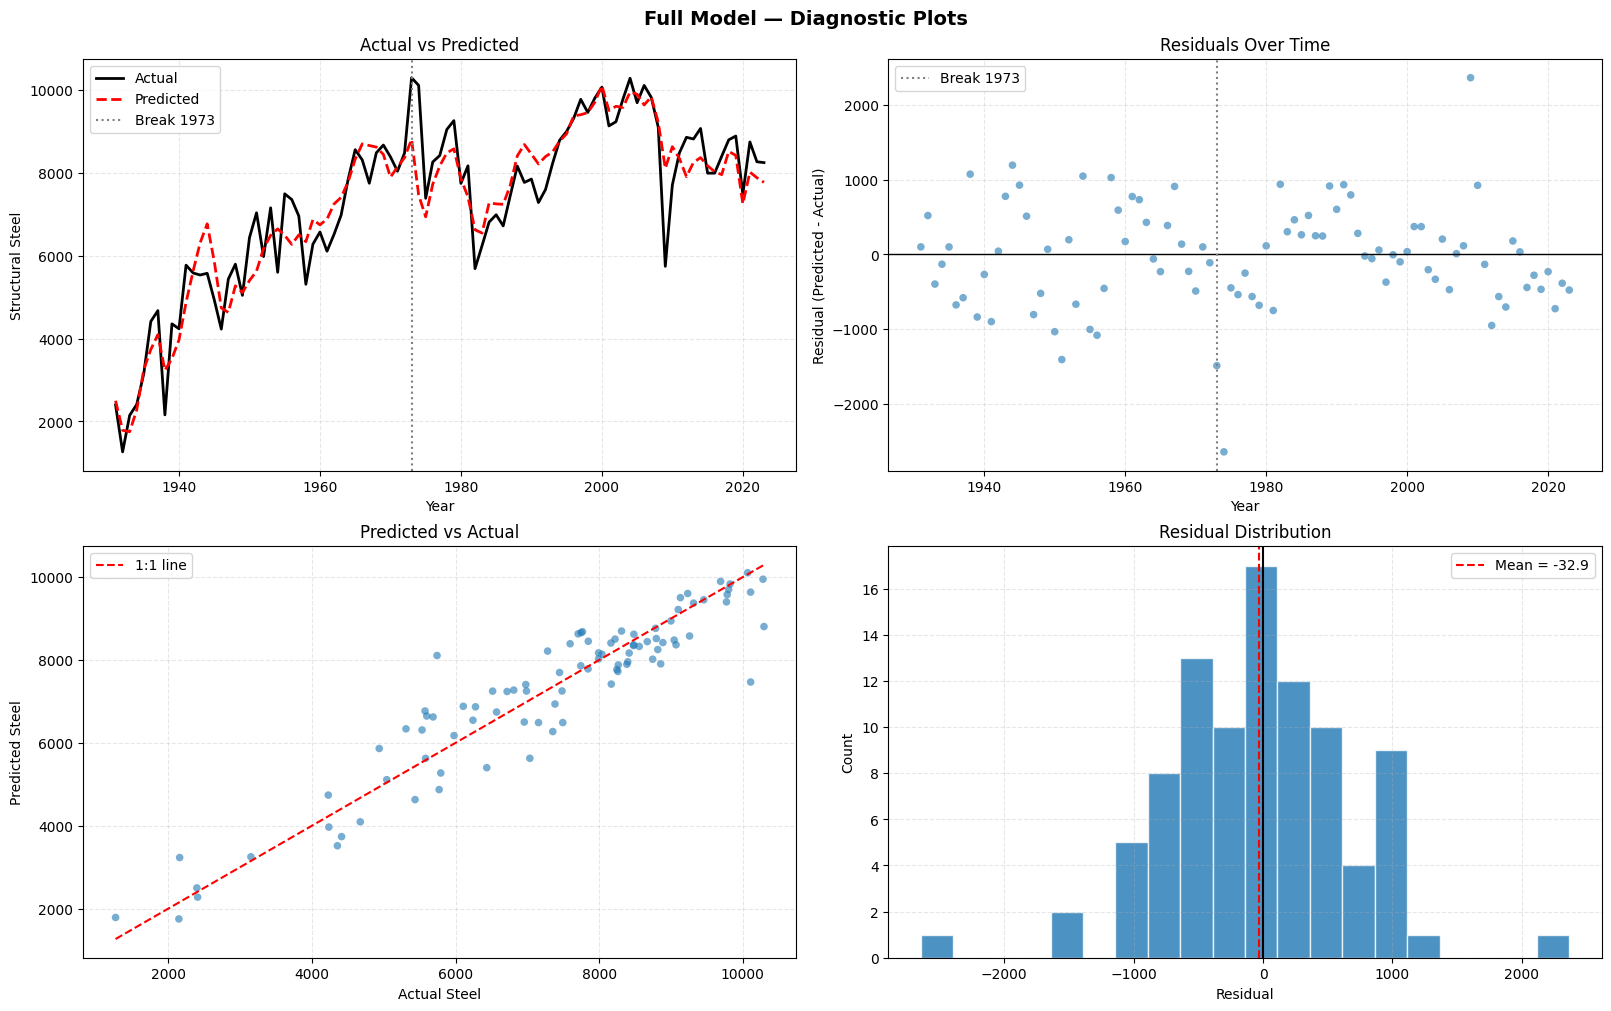


=== Coefficients (store these for forecasting) ===
intercept      : -43.383336
gdp            : 2.440521
pop            : 1.862711
energy         : -1.886032
post*gdp       : -2.071520
post*pop       : -3.530295
post*energy    : 3.762290
post           : 72.513912


In [946]:
from numpy.linalg import lstsq
import numpy as np
import matplotlib.pyplot as plt

# ── 1. Rebuild full model (GDP + Population + Energy) ────────────────────────
df_model = df_elasticities.loc[1931:2023].copy()
df_model = df_model.dropna(subset=['structural-total', 'gdp_ssp2',
                                    'pop_ssp2', 'energy usage'])

log_steel  = np.log(df_model['structural-total'].values)
log_gdp    = np.log(df_model['gdp_ssp2'].values)
log_pop    = np.log(df_model['pop_ssp2'].values)
log_energy = np.log(df_model['energy usage'].values)
post       = (df_model.index > 1973).astype(float)

X = np.column_stack([
    log_gdp,
    log_pop,
    log_energy,
    post * log_gdp,
    post * log_pop,
    post * log_energy,
    post,
])

X_const = np.column_stack([np.ones(len(X)), X])
coeffs, _, _, _ = lstsq(X_const, log_steel, rcond=None)

log_steel_pred = X_const @ coeffs
steel_pred     = np.exp(log_steel_pred)
actual         = df_model['structural-total'].values

# ── 2. Full diagnostics ───────────────────────────────────────────────────────
residuals = steel_pred - actual
ss_res    = np.sum((actual - steel_pred) ** 2)
ss_tot    = np.sum((actual - np.mean(actual)) ** 2)
r2        = 1 - ss_res / ss_tot
rmse      = np.sqrt(np.mean((actual - steel_pred) ** 2))
mape      = np.mean(np.abs((actual - steel_pred) / actual)) * 100
bias      = np.mean(steel_pred - actual)

print(f"=== Final Model Metrics ===")
print(f"R²:   {r2:.4f}")
print(f"RMSE: {rmse:.1f}")
print(f"MAPE: {mape:.2f}%")
print(f"Bias: {bias:.1f}")

# ── 3. Four-panel diagnostic plot ─────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 10), constrained_layout=True)

# Actual vs predicted
ax = axes[0, 0]
ax.plot(df_model.index, actual,     color='black', lw=2, label='Actual')
ax.plot(df_model.index, steel_pred, color='red',   lw=2,
        linestyle='--', label='Predicted')
ax.axvline(1973, color='grey', linestyle=':', lw=1.5, label='Break 1973')
ax.set_title('Actual vs Predicted')
ax.set_xlabel('Year')
ax.set_ylabel('Structural Steel')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.3)

# Residuals over time
ax = axes[0, 1]
ax.scatter(df_model.index, residuals, alpha=0.6, s=30,
           color='tab:blue', edgecolor='none')
ax.axhline(0,    color='black', lw=1)
ax.axvline(1973, color='grey',  linestyle=':', lw=1.5, label='Break 1973')
ax.set_title('Residuals Over Time')
ax.set_xlabel('Year')
ax.set_ylabel('Residual (Predicted - Actual)')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.3)

# Predicted vs actual scatter
ax = axes[1, 0]
ax.scatter(actual, steel_pred, alpha=0.6, s=30,
           color='tab:blue', edgecolor='none')
min_val = min(actual.min(), steel_pred.min())
max_val = max(actual.max(), steel_pred.max())
ax.plot([min_val, max_val], [min_val, max_val],
        color='red', lw=1.5, linestyle='--', label='1:1 line')
ax.set_title('Predicted vs Actual')
ax.set_xlabel('Actual Steel')
ax.set_ylabel('Predicted Steel')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.3)

# Residual distribution
ax = axes[1, 1]
ax.hist(residuals, bins=20, color='tab:blue', edgecolor='white', alpha=0.8)
ax.axvline(0,                color='black', lw=1.5)
ax.axvline(residuals.mean(), color='red',   lw=1.5,
           linestyle='--', label=f'Mean = {residuals.mean():.1f}')
ax.set_title('Residual Distribution')
ax.set_xlabel('Residual')
ax.set_ylabel('Count')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.3)

fig.suptitle('Full Model — Diagnostic Plots', fontsize=14, fontweight='bold')
plt.show()

# ── 4. Store coefficients for forecasting ────────────────────────────────────
print(f"\n=== Coefficients (store these for forecasting) ===")
names = ['intercept', 'gdp', 'pop', 'energy',
         'post*gdp', 'post*pop', 'post*energy', 'post']
for name, coef in zip(names, coeffs):
    print(f"{name:<15}: {coef:.6f}")

=== Forecast Elasticities (post-1973) ===
Intercept: 29.1306
GDP:       0.3690
Pop:       -1.6676
Energy:    1.8763
SSP1 — 2050: 7,294 | 2100: 9,368
SSP2 — 2050: 7,074 | 2100: 8,022
SSP3 — 2050: 6,978 | 2100: 5,673
SSP4 — 2050: 7,896 | 2100: 12,446
SSP5 — 2050: 6,639 | 2100: 8,512


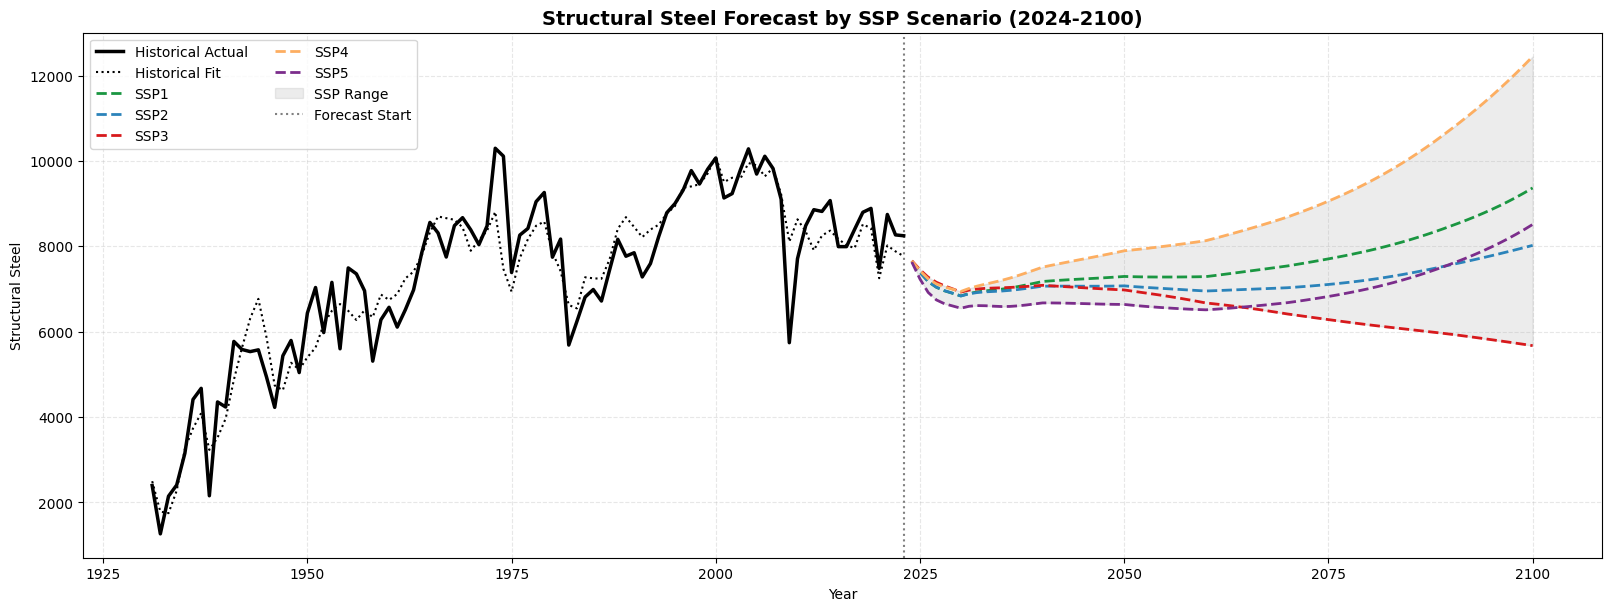

In [947]:
# ── 1. Post-1973 elasticities from fitted model ───────────────────────────────
intercept_post = coeffs[0] + coeffs[7]
gdp_e_post     = coeffs[1] + coeffs[4]
pop_e_post     = coeffs[2] + coeffs[5]
energy_e_post  = coeffs[3] + coeffs[6]

print("=== Forecast Elasticities (post-1973) ===")
print(f"Intercept: {intercept_post:.4f}")
print(f"GDP:       {gdp_e_post:.4f}")
print(f"Pop:       {pop_e_post:.4f}")
print(f"Energy:    {energy_e_post:.4f}")

# ── 2. SSP scenario definitions ───────────────────────────────────────────────
ssps = {
    'SSP1': {'gdp': 'gdp_ssp1', 'pop': 'pop_ssp1'},
    'SSP2': {'gdp': 'gdp_ssp2', 'pop': 'pop_ssp2'},
    'SSP3': {'gdp': 'gdp_ssp3', 'pop': 'pop_ssp3'},
    'SSP4': {'gdp': 'gdp_ssp4', 'pop': 'pop_ssp4'},
    'SSP5': {'gdp': 'gdp_ssp5', 'pop': 'pop_ssp5'},
}

ssp_colors = {
    'SSP1': '#1a9641',
    'SSP2': '#2b83ba',
    'SSP3': '#d7191c',
    'SSP4': '#fdae61',
    'SSP5': '#7b2d8b',
}

# ── 3. Build forecast dataframes 2024-2100 ────────────────────────────────────
forecast_years = np.arange(2024, 2101)
forecast_dfs   = {}

for ssp_name, cols in ssps.items():
    df_fore = pd.DataFrame(index=forecast_years)
    df_fore.index.name = 'year'

    # Pull each variable from its source df
    df_fore['gdp']    = df_gdp.loc[2024:2100, cols['gdp']]
    df_fore['pop']    = df_population.loc[2024:2100, cols['pop']]
    df_fore['energy'] = df_energy_use.loc[2024:2100, 'energy usage']

    # Forecast steel
    log_steel_fore = (
        intercept_post
        + gdp_e_post    * np.log(df_fore['gdp'].values)
        + pop_e_post    * np.log(df_fore['pop'].values)
        + energy_e_post * np.log(df_fore['energy'].values)
    )
    df_fore['steel_forecast'] = np.exp(log_steel_fore)
    forecast_dfs[ssp_name] = df_fore

    print(f"{ssp_name} — 2050: {df_fore.loc[2050, 'steel_forecast']:,.0f} | "
          f"2100: {df_fore.loc[2100, 'steel_forecast']:,.0f}")

# ── 4. Plot ───────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(16, 6), constrained_layout=True)

# Historical actual
ax.plot(df_steel.index, df_steel['structural-total'],
        color='black', lw=2.5, label='Historical Actual', zorder=5)

# Historical fitted
ax.plot(df_model.index, steel_pred,
        color='black', lw=1.5, linestyle=':', label='Historical Fit', zorder=4)

# SSP forecasts
for ssp_name, df_fore in forecast_dfs.items():
    ax.plot(df_fore.index, df_fore['steel_forecast'],
            color=ssp_colors[ssp_name], lw=2,
            linestyle='--', label=ssp_name)

# Uncertainty shading across SSP range
all_forecasts = np.array([df['steel_forecast'].values
                          for df in forecast_dfs.values()])
ax.fill_between(forecast_years,
                all_forecasts.min(axis=0),
                all_forecasts.max(axis=0),
                alpha=0.15, color='grey', label='SSP Range')

ax.axvline(2023, color='grey', linestyle=':', lw=1.5, label='Forecast Start')
ax.set_xlabel('Year')
ax.set_ylabel('Structural Steel')
ax.set_title('Structural Steel Forecast by SSP Scenario (2024-2100)',
             fontsize=14, fontweight='bold')
ax.legend(loc='upper left', ncol=2)
ax.grid(True, linestyle='--', alpha=0.3)
plt.show()

## Leveque et al Method

Using the equation for forecasting presented in Leveque et al (2018), which is a common forecasting equation as a jumping off point. This will not have a numerical tag moving forward. 

In [949]:
stuctural_constant

0.049

In [959]:
def forecast_structural_steel(
    df_population,
    df_gdp,
    structural_constant,
    gdp_elast,
    pop_elast,
    scenarios=range(1, 6),
    start_year=2024,
    end_year=2100,
    scale=1e5,
):
    df_population = df_population.copy()
    df_gdp = df_gdp.copy()
    df_population.index = df_population.index.astype(int)
    df_gdp.index = df_gdp.index.astype(int)

    forecast_years = np.arange(start_year, end_year + 1)

    data = {}
    for s in scenarios:
        pop_col = f"pop_ssp{s}"
        gdp_col = f"total_gdp_ssp{s}"

        pop_fore = df_population.loc[forecast_years, pop_col]
        gdp_fore = df_gdp.loc[forecast_years, gdp_col]

        steel_fore_vals = structural_constant * (gdp_fore ** gdp_elast) * (pop_fore ** pop_elast)

        data[f"structural_ssp{s}"] = steel_fore_vals / scale

    df_steel_forecast = pd.DataFrame(data, index=forecast_years)
    df_steel_forecast.index.name = "year"

    return df_steel_forecast

In [960]:
df_steel_forecast = forecast_structural_steel(
    df_population=df_population,
    df_gdp=df_total_gdp,
    structural_constant=stuctural_constant,  
    gdp_elast=gdp_elast,
    pop_elast=pop_elast,
    scenarios=range(1, 6),      # SSP1–SSP5
    start_year=1931,
    end_year=2100,
    scale=1.2e7
)

<Axes: xlabel='year'>

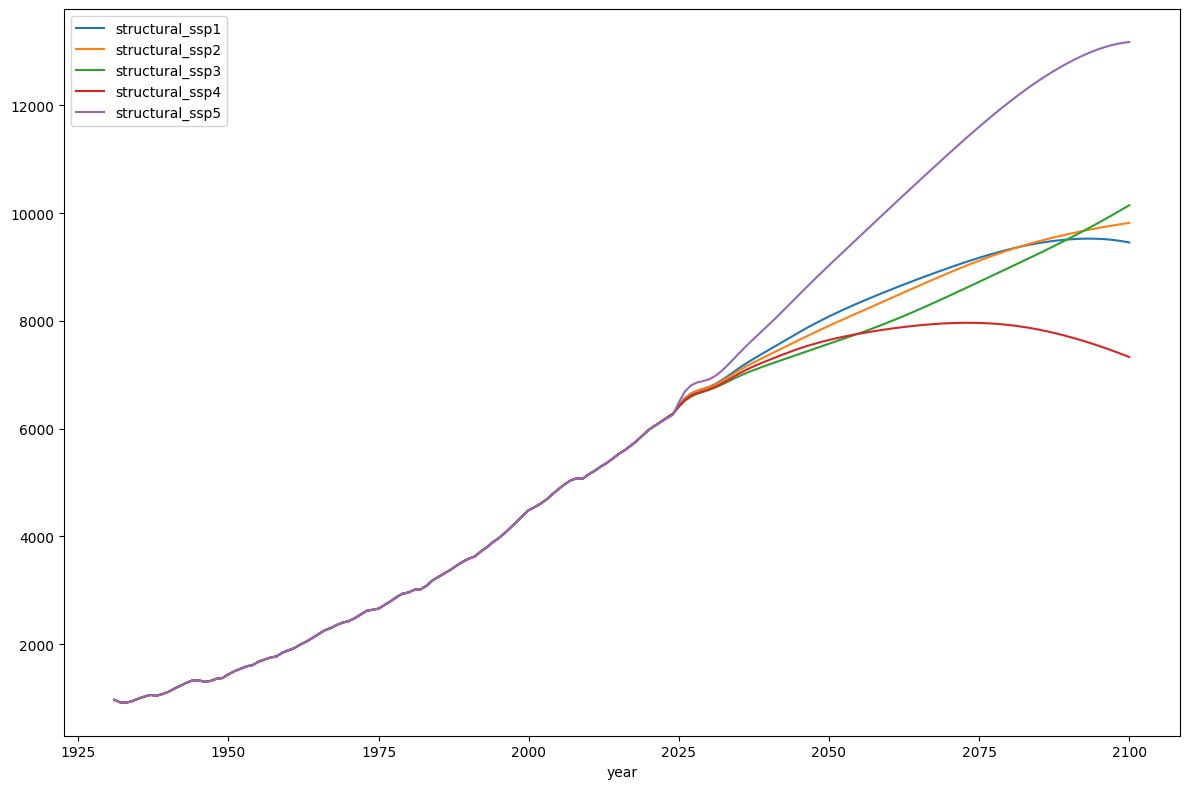

In [961]:
df_steel_forecast.plot()

## Method 1

This method includes final energy usage as a proxy for energy demand, as a difference from the leveque method

In [962]:
def forecast_structural_steel_1(
    df_population,
    df_gdp,
    df_energy,
    structural_constant,
    gdp_elast,
    pop_elast,
    energy_elast,
    energy_col="energy",
    scenarios=range(1, 6),
    start_year=2024,
    end_year=2100,
    scale=1e5,
):
    df_population = df_population.copy()
    df_gdp = df_gdp.copy()
    df_energy = df_energy.copy()
    df_population.index = df_population.index.astype(int)
    df_gdp.index = df_gdp.index.astype(int)
    df_energy.index = df_energy.index.astype(int)

    forecast_years = np.arange(start_year, end_year + 1)

    energy_fore = df_energy.loc[forecast_years, energy_col]

    data = {}
    for s in scenarios:
        pop_col = f"pop_ssp{s}"
        gdp_col = f"total_gdp_ssp{s}"

        pop_fore = df_population.loc[forecast_years, pop_col]
        gdp_fore = df_gdp.loc[forecast_years, gdp_col]

        steel_fore_vals = (
            structural_constant
            * (gdp_fore ** gdp_elast)
            * (pop_fore ** pop_elast)
            * (energy_fore ** energy_elast)
        )

        data[f"structural_ssp{s}"] = steel_fore_vals / scale

    df_steel_forecast = pd.DataFrame(data, index=forecast_years)
    df_steel_forecast.index.name = "year"

    return df_steel_forecast

In [963]:
df_steel_forecast_1 = forecast_structural_steel_1(
    df_population=df_population,
    df_gdp=df_total_gdp,
    df_energy=df_energy_use,
    structural_constant=stuctural_constant,  # your spelling
    gdp_elast=gdp_elast,
    pop_elast=pop_elast,
    energy_elast=energy_elast,
    energy_col='energy usage',
    scenarios=range(1, 6),      # SSP1–SSP5
    start_year=1931,
    end_year=2100,
    scale=1.25e8
)


<Axes: xlabel='year'>

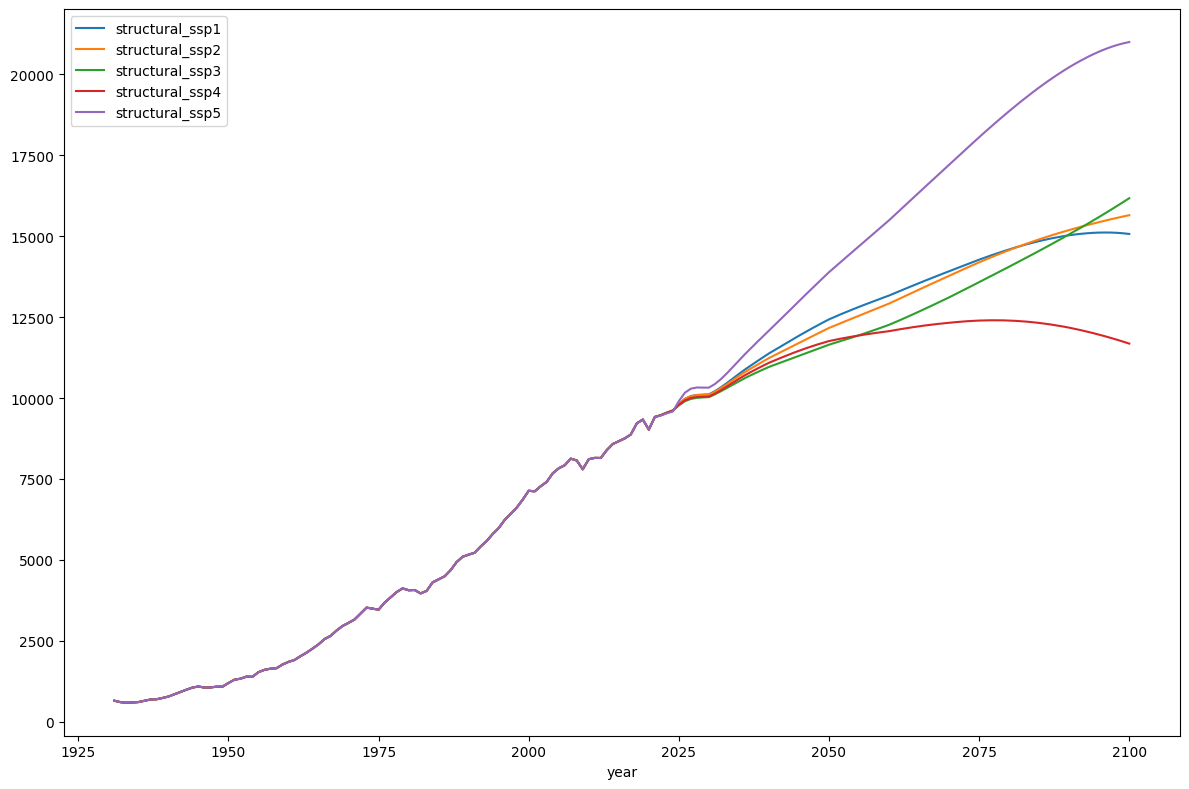

In [964]:
df_steel_forecast_1.plot()

In [965]:
df_steel_forecast_1.loc[2020:2026]

,structural_ssp1,structural_ssp2,structural_ssp3,structural_ssp4,structural_ssp5
year,,,,,
2020,9025.792069,9025.792069,9025.792069,9025.792069,9025.792069
2021,9417.096853,9417.075285,9418.435177,9417.758708,9413.771272
2022,9470.449030,9470.423297,9474.104921,9472.329819,9461.370110
2023,9545.660935,9545.690823,9552.342832,9549.267138,9529.079964
2024,9610.128367,9610.315193,9620.265795,9615.909466,9584.998132
2025,9812.722561,9811.404355,9775.469923,9790.080489,9905.782143
2026,9976.344701,9973.981526,9901.834845,9929.405199,10165.316736


## Method 2

This method tries looking at these with a logarithmic relationship

In [966]:
def forecast_structural_steel_2(
    df_population,
    df_gdp,
    df_energy,
    structural_constant,
    gdp_elast,
    pop_elast,
    energy_elast,
    energy_col="energy",
    scenarios=range(1, 6),
    start_year=2024,
    end_year=2100,
    scale=1e5,
):
    df_population = df_population.copy()
    df_gdp = df_gdp.copy()
    df_energy = df_energy.copy()
    df_population.index = df_population.index.astype(int)
    df_gdp.index = df_gdp.index.astype(int)
    df_energy.index = df_energy.index.astype(int)

    forecast_years = np.arange(start_year, end_year + 1)

    energy_fore = df_energy.loc[forecast_years, energy_col]

    data = {}
    for s in scenarios:
        pop_col = f"pop_ssp{s}"
        gdp_col = f"total_gdp_ssp{s}"

        pop_fore = df_population.loc[forecast_years, pop_col]
        gdp_fore = df_gdp.loc[forecast_years, gdp_col]

        steel_fore_vals = (
            structural_constant
            * (gdp_elast * np.log(gdp_fore))
            * (pop_elast * np.log(pop_fore))
            * (energy_elast * np.log(energy_fore))
        )

        data[f"structural_ssp{s}"] = steel_fore_vals / scale

    df_steel_forecast = pd.DataFrame(data, index=forecast_years)
    df_steel_forecast.index.name = "year"

    return df_steel_forecast

In [967]:
df_steel_forecast_2 = forecast_structural_steel_2(
    df_population=df_population,
    df_gdp=df_total_gdp,
    df_energy=df_energy_use,
    structural_constant=stuctural_constant,  # your spelling
    gdp_elast=gdp_elast,
    pop_elast=pop_elast,
    energy_elast=energy_elast,
    energy_col='energy usage',
    scenarios=range(1, 6),      # SSP1–SSP5
    start_year=1931,
    end_year=2100,
    scale=0.4e-2
)

<Axes: xlabel='year'>

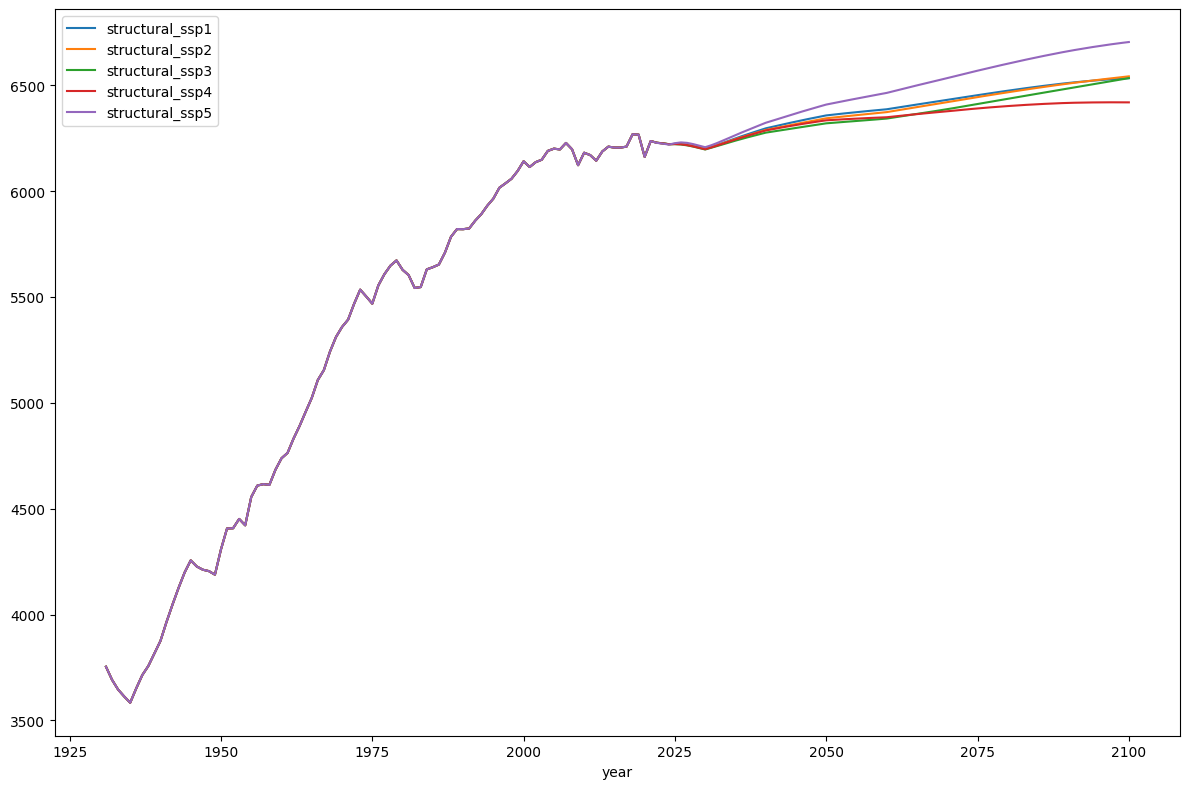

In [968]:
df_steel_forecast_2.plot()

## Method 3

This method tries using a logarithmic relationship for GDP, exponential relationship for Population, and linear relationship for energy use

In [969]:
def forecast_structural_steel_3(
    df_population,
    df_gdp,
    df_energy,
    structural_constant,
    gdp_elast,
    pop_elast,
    energy_elast,
    energy_col="energy",
    scenarios=range(1, 6),
    start_year=2024,
    end_year=2100,
    scale=1e5,
):
    df_population = df_population.copy()
    df_gdp = df_gdp.copy()
    df_energy = df_energy.copy()
    df_population.index = df_population.index.astype(int)
    df_gdp.index = df_gdp.index.astype(int)
    df_energy.index = df_energy.index.astype(int)

    forecast_years = np.arange(start_year, end_year + 1)

    energy_fore = df_energy.loc[forecast_years, energy_col]

    data = {}
    for s in scenarios:
        pop_col = f"pop_ssp{s}"
        gdp_col = f"total_gdp_ssp{s}"

        pop_fore = df_population.loc[forecast_years, pop_col]
        gdp_fore = df_gdp.loc[forecast_years, gdp_col]

        steel_fore_vals = (
            structural_constant
            * (gdp_elast * np.log(gdp_fore))
            * (pop_fore** pop_elast)
            * (energy_fore * energy_elast)
        )

        data[f"structural_ssp{s}"] = steel_fore_vals / scale

    df_steel_forecast = pd.DataFrame(data, index=forecast_years)
    df_steel_forecast.index.name = "year"

    return df_steel_forecast

In [970]:
df_steel_forecast_3 = forecast_structural_steel_3(
    df_population=df_population,
    df_gdp=df_total_gdp,
    df_energy=df_energy_use,
    structural_constant=stuctural_constant,  # your spelling
    gdp_elast=gdp_elast,
    pop_elast=pop_elast,
    energy_elast=energy_elast,
    energy_col='energy usage',
    scenarios=range(1, 6),      # SSP1–SSP5
    start_year=1931,
    end_year=2100,
    scale=1.75e5
)

<Axes: xlabel='year'>

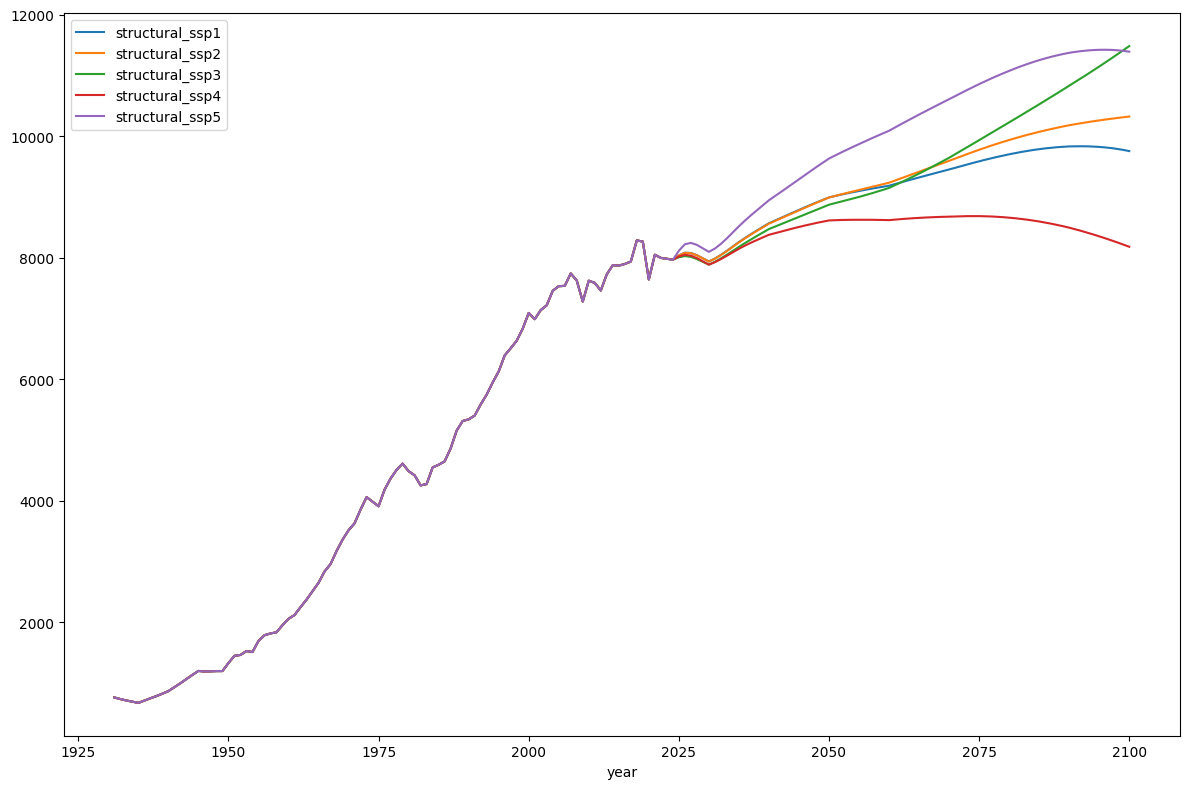

In [971]:
df_steel_forecast_3.plot()

## Model 4

This model uses logarithmic for gdp and population and linear for energy use

In [972]:
def forecast_structural_steel_4(
    df_population,
    df_gdp,
    df_energy,
    structural_constant,
    gdp_elast,
    pop_elast,
    energy_elast,
    energy_col="energy",
    scenarios=range(1, 6),
    start_year=2024,
    end_year=2100,
    scale=1e5,
):
    df_population = df_population.copy()
    df_gdp = df_gdp.copy()
    df_energy = df_energy.copy()
    df_population.index = df_population.index.astype(int)
    df_gdp.index = df_gdp.index.astype(int)
    df_energy.index = df_energy.index.astype(int)

    forecast_years = np.arange(start_year, end_year + 1)

    energy_fore = df_energy.loc[forecast_years, energy_col]

    data = {}
    for s in scenarios:
        pop_col = f"pop_ssp{s}"
        gdp_col = f"total_gdp_ssp{s}"

        pop_fore = df_population.loc[forecast_years, pop_col]
        gdp_fore = df_gdp.loc[forecast_years, gdp_col]

        steel_fore_vals = (
            structural_constant
            * (gdp_elast * np.log(gdp_fore))
            * (pop_elast * np.log(pop_fore))
            * (energy_fore * energy_elast)
        )

        data[f"structural_ssp{s}"] = steel_fore_vals / scale

    df_steel_forecast = pd.DataFrame(data, index=forecast_years)
    df_steel_forecast.index.name = "year"

    return df_steel_forecast

In [973]:
df_steel_forecast_4 = forecast_structural_steel_4(
    df_population=df_population,
    df_gdp=df_total_gdp,
    df_energy=df_energy_use,
    structural_constant=stuctural_constant,  # your spelling
    gdp_elast=gdp_elast,
    pop_elast=pop_elast,
    energy_elast=energy_elast,
    energy_col='energy usage',
    scenarios=range(1, 6),      # SSP1–SSP5
    start_year=1931,
    end_year=2100,
    scale=0.6e-1
)

<Axes: xlabel='year'>

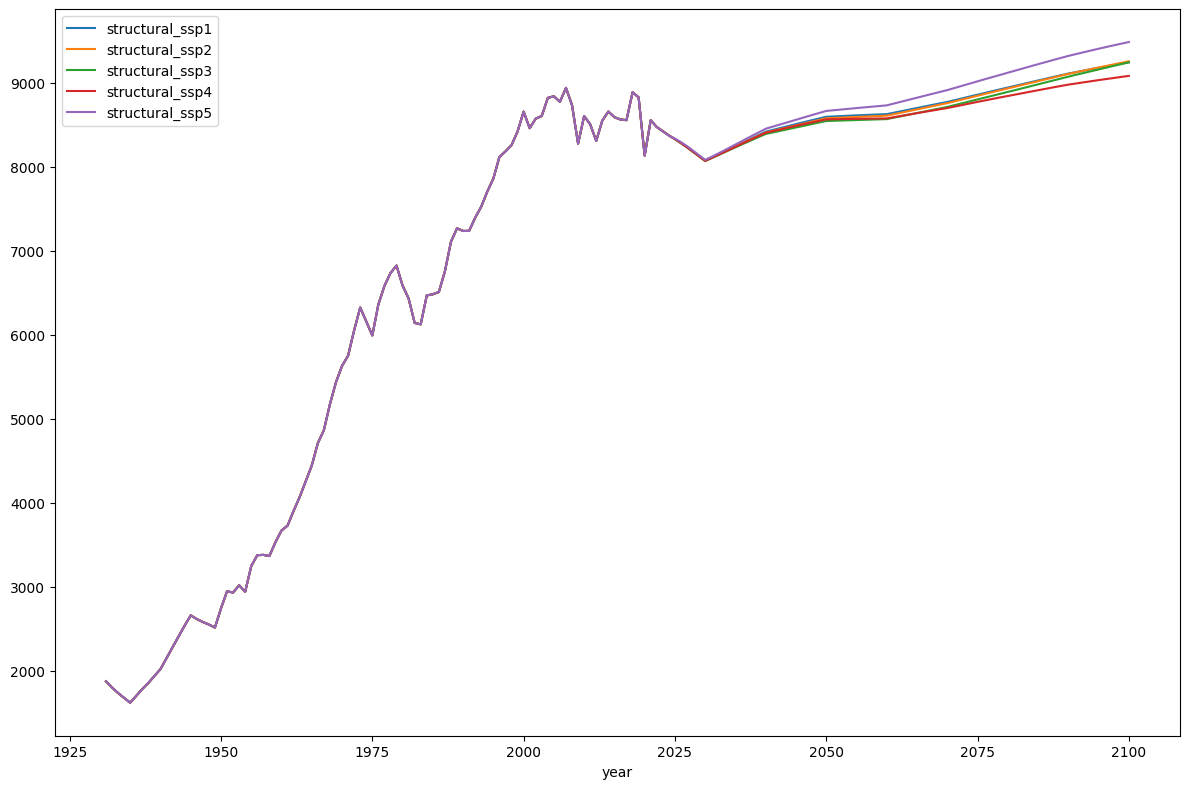

In [974]:
df_steel_forecast_4.plot()

## Model 5

This model uses logarithmic for gdp and population and exponential for energy use

In [975]:
def forecast_structural_steel_5(
    df_population,
    df_gdp,
    df_energy,
    structural_constant,
    gdp_elast,
    pop_elast,
    energy_elast,
    energy_col="energy",
    scenarios=range(1, 6),
    start_year=2024,
    end_year=2100,
    scale=1e5,
):
    df_population = df_population.copy()
    df_gdp = df_gdp.copy()
    df_energy = df_energy.copy()
    df_population.index = df_population.index.astype(int)
    df_gdp.index = df_gdp.index.astype(int)
    df_energy.index = df_energy.index.astype(int)

    forecast_years = np.arange(start_year, end_year + 1)

    energy_fore = df_energy.loc[forecast_years, energy_col]

    data = {}
    for s in scenarios:
        pop_col = f"pop_ssp{s}"
        gdp_col = f"total_gdp_ssp{s}"

        pop_fore = df_population.loc[forecast_years, pop_col]
        gdp_fore = df_gdp.loc[forecast_years, gdp_col]

        steel_fore_vals = (
            structural_constant
            * (gdp_elast * np.log(gdp_fore))
            * (pop_elast * np.log(pop_fore))
            * (energy_fore ** energy_elast)
        )

        data[f"structural_ssp{s}"] = steel_fore_vals / scale

    df_steel_forecast = pd.DataFrame(data, index=forecast_years)
    df_steel_forecast.index.name = "year"

    return df_steel_forecast

In [976]:
df_steel_forecast_5 = forecast_structural_steel_5(
    df_population=df_population,
    df_gdp=df_total_gdp,
    df_energy=df_energy_use,
    structural_constant=stuctural_constant,  # your spelling
    gdp_elast=gdp_elast,
    pop_elast=pop_elast,
    energy_elast=energy_elast,
    energy_col='energy usage',
    scenarios=range(1, 6),      # SSP1–SSP5
    start_year=1931,
    end_year=2100,
    scale=1.75e-2
)

<Axes: xlabel='year'>

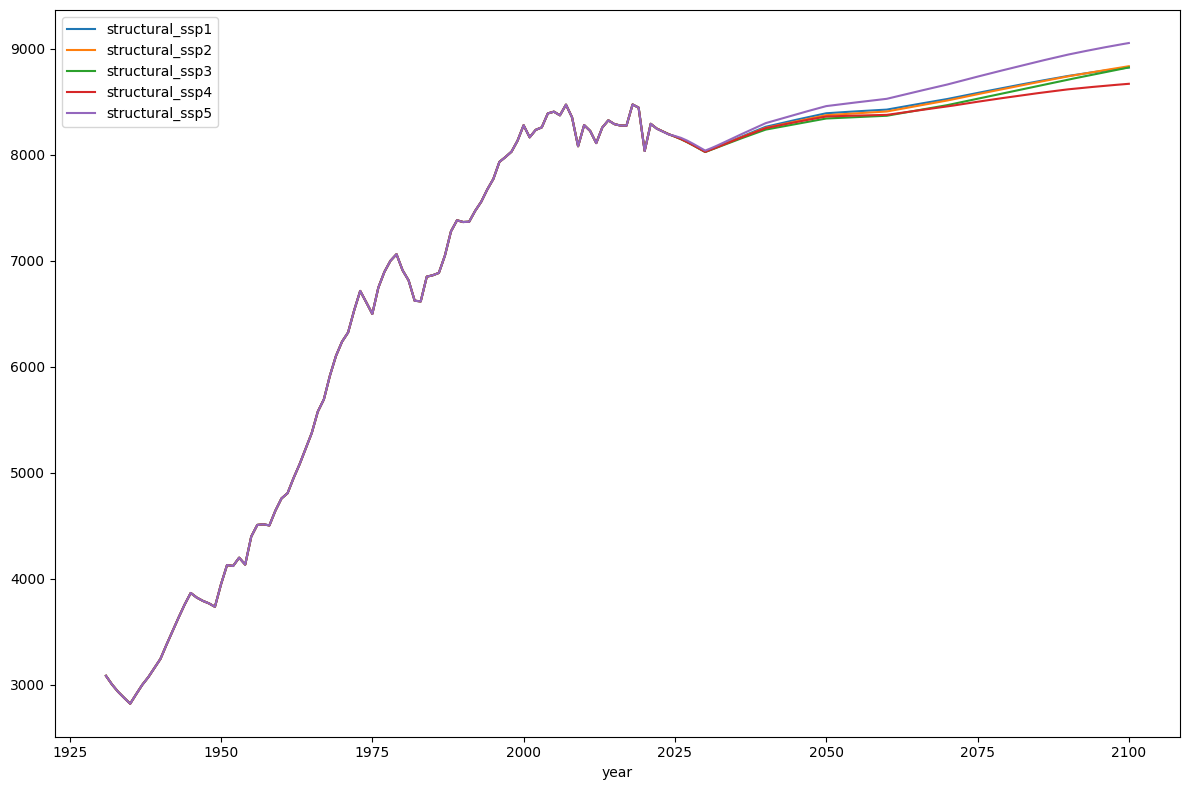

In [977]:
df_steel_forecast_5.plot()

## Model 6

I wanted to return to the leveque method to see what the relationship with those two variables would look like

In [978]:
def forecast_structural_steel_6(
    df_population,
    df_gdp,
    structural_constant,
    gdp_elast,
    pop_elast,
    scenarios=range(1, 6),
    start_year=2024,
    end_year=2100,
    scale=1e5,
):
    df_population = df_population.copy()
    df_gdp = df_gdp.copy()
    df_population.index = df_population.index.astype(int)
    df_gdp.index = df_gdp.index.astype(int)

    forecast_years = np.arange(start_year, end_year + 1)

    data = {}
    for s in scenarios:
        pop_col = f"pop_ssp{s}"
        gdp_col = f"total_gdp_ssp{s}"

        pop_fore = df_population.loc[forecast_years, pop_col]
        gdp_fore = df_gdp.loc[forecast_years, gdp_col]

        steel_fore_vals = (
        structural_constant
        * (gdp_elast * np.log(gdp_fore))
        * (pop_elast * np.log(pop_fore))
        )

        data[f"structural_ssp{s}"] = steel_fore_vals / scale

    df_steel_forecast = pd.DataFrame(data, index=forecast_years)
    df_steel_forecast.index.name = "year"

    return df_steel_forecast

In [979]:
df_steel_forecast_6 = forecast_structural_steel_6(
    df_population=df_population,
    df_gdp=df_total_gdp,
    structural_constant=stuctural_constant,  
    gdp_elast=gdp_elast,
    pop_elast=pop_elast,
    scenarios=range(1, 6),      # SSP1–SSP5
    start_year=1931,
    end_year=2100,
    scale=1e-3
)

<Axes: xlabel='year'>

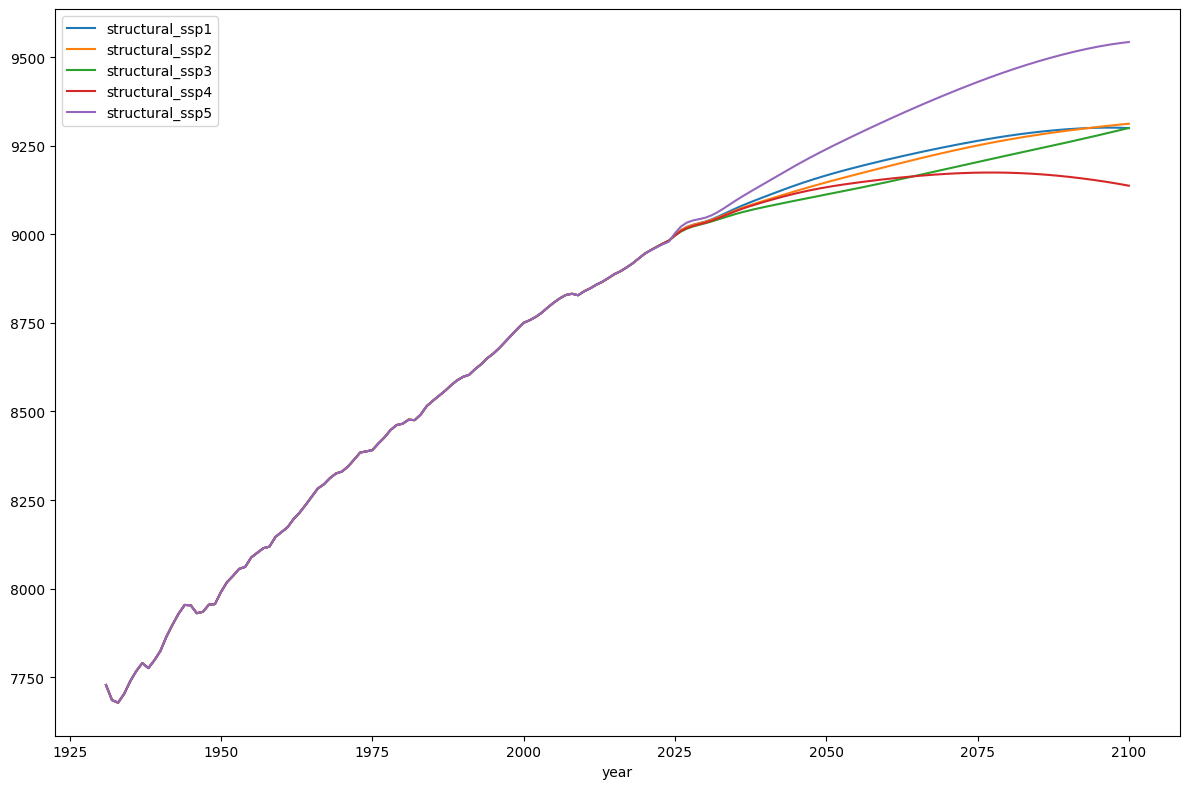

In [980]:
df_steel_forecast_6.plot()

## Model 7

This method explores a linear relationship between the original variables 

In [981]:
def forecast_structural_steel_7(
    df_population,
    df_gdp,
    structural_constant,
    gdp_elast,
    pop_elast,
    scenarios=range(1, 6),
    start_year=2024,
    end_year=2100,
    scale=1e5,
):
    df_population = df_population.copy()
    df_gdp = df_gdp.copy()
    df_population.index = df_population.index.astype(int)
    df_gdp.index = df_gdp.index.astype(int)

    forecast_years = np.arange(start_year, end_year + 1)

    data = {}
    for s in scenarios:
        pop_col = f"pop_ssp{s}"
        gdp_col = f"total_gdp_ssp{s}"

        pop_fore = df_population.loc[forecast_years, pop_col]
        gdp_fore = df_gdp.loc[forecast_years, gdp_col]

        steel_fore_vals = (
        structural_constant
        * (gdp_elast * gdp_fore)
        * (pop_elast * pop_fore)
        )

        data[f"structural_ssp{s}"] = steel_fore_vals / scale

    df_steel_forecast = pd.DataFrame(data, index=forecast_years)
    df_steel_forecast.index.name = "year"

    return df_steel_forecast

In [982]:
df_steel_forecast_7 = forecast_structural_steel_7(
    df_population=df_population,
    df_gdp=df_total_gdp,
    structural_constant=stuctural_constant,  
    gdp_elast=gdp_elast,
    pop_elast=pop_elast,
    scenarios=range(1, 6),      # SSP1–SSP5
    start_year=1931,
    end_year=2100,
    scale=1e16
)

<Axes: xlabel='year'>

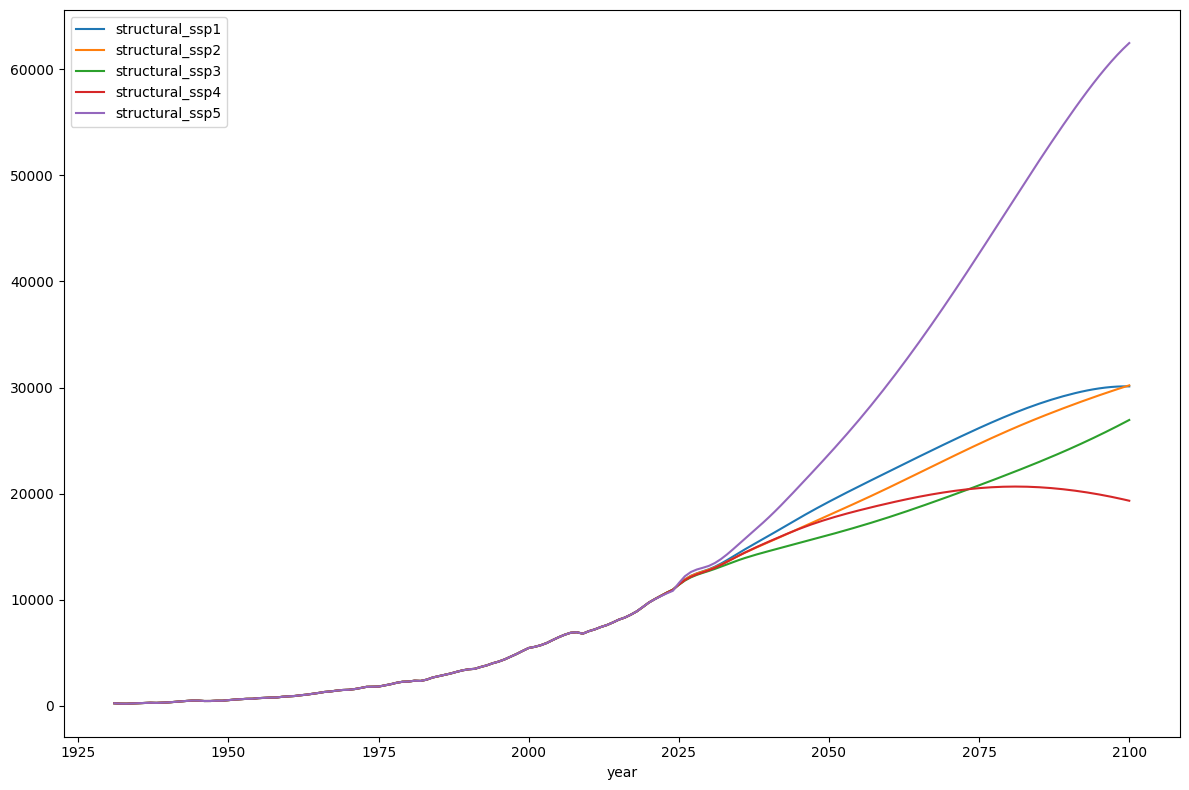

In [983]:
df_steel_forecast_7.plot()

## Model 8

In [984]:
def forecast_structural_steel_8(
    df_population,
    df_gdp,
    df_energy,
    structural_constant,
    gdp_elast,
    pop_elast,
    energy_elast,
    energy_col="energy",
    scenarios=range(1, 6),
    start_year=2024,
    end_year=2100,
    scale=1e5,
):
    df_population = df_population.copy()
    df_gdp = df_gdp.copy()
    df_energy = df_energy.copy()
    df_population.index = df_population.index.astype(int)
    df_gdp.index = df_gdp.index.astype(int)
    df_energy.index = df_energy.index.astype(int)

    forecast_years = np.arange(start_year, end_year + 1)

    energy_fore = df_energy.loc[forecast_years, energy_col]

    data = {}
    for s in scenarios:
        pop_col = f"pop_ssp{s}"
        gdp_col = f"total_gdp_ssp{s}"

        pop_fore = df_population.loc[forecast_years, pop_col]
        gdp_fore = df_gdp.loc[forecast_years, gdp_col]

        steel_fore_vals = (
            structural_constant
            * (gdp_elast * np.log(gdp_fore))
            * (pop_fore ** pop_elast)
            * (energy_elast * np.log(gdp_fore))
        )

        data[f"structural_ssp{s}"] = steel_fore_vals / scale

    df_steel_forecast = pd.DataFrame(data, index=forecast_years)
    df_steel_forecast.index.name = "year"

    return df_steel_forecast

In [985]:
df_steel_forecast_8 = forecast_structural_steel_8(
    df_population=df_population,
    df_gdp=df_total_gdp,
    df_energy=df_energy_use,
    structural_constant=stuctural_constant,  # your spelling
    gdp_elast=gdp_elast,
    pop_elast=pop_elast,
    energy_elast=energy_elast,
    energy_col='energy usage',
    scenarios=range(1, 6),      # SSP1–SSP5
    start_year=1931,
    end_year=2100,
    scale=0.75e5
)

<Axes: xlabel='year'>

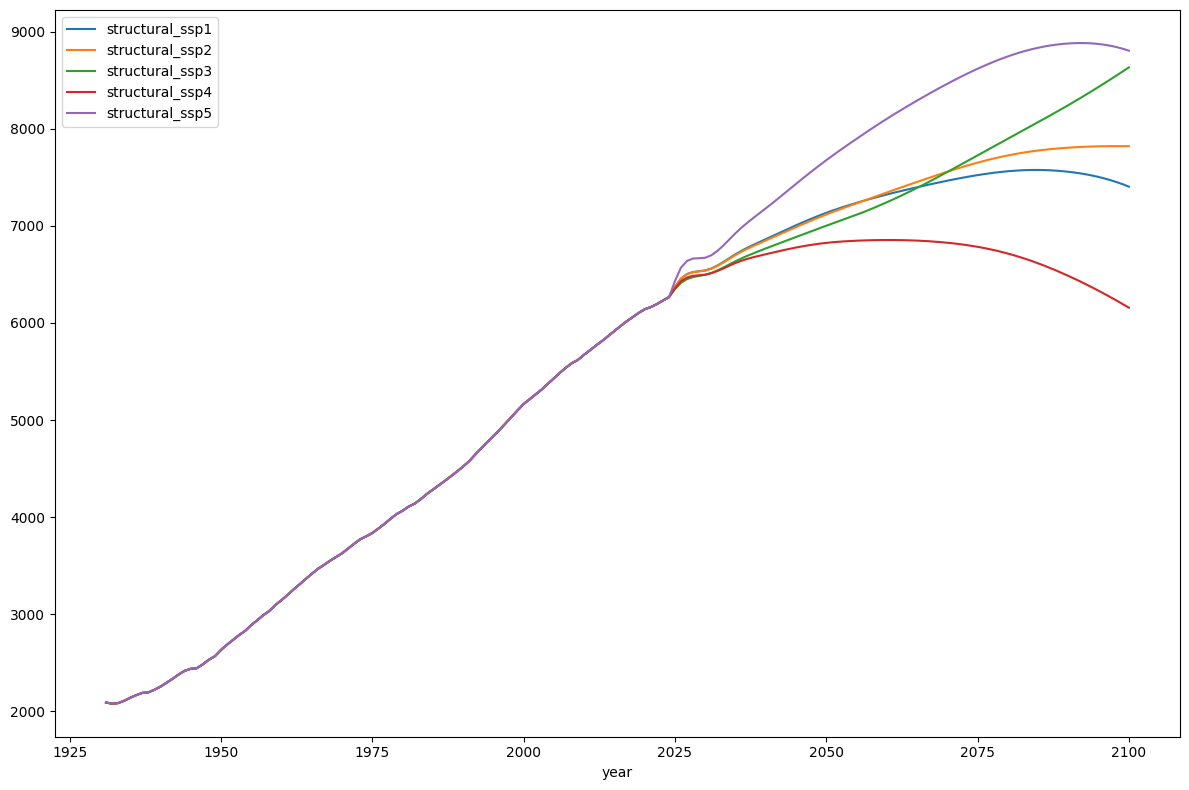

In [986]:
df_steel_forecast_8.plot()

## Model 9

In [987]:
def forecast_structural_steel_9(
    df_gdp,
    df_energy,
    structural_constant,
    gdp_elast,
    energy_elast,
    energy_col="energy",
    scenarios=range(1, 6),
    start_year=2024,
    end_year=2100,
    scale=1e5,
):
    df_gdp = df_gdp.copy()
    df_energy = df_energy.copy()
    df_gdp.index = df_gdp.index.astype(int)
    df_energy.index = df_energy.index.astype(int)

    forecast_years = np.arange(start_year, end_year + 1)

    energy_fore = df_energy.loc[forecast_years, energy_col]

    data = {}
    for s in scenarios:
        gdp_col = f"total_gdp_ssp{s}"

        gdp_fore = df_gdp.loc[forecast_years, gdp_col]

        steel_fore_vals = (
            structural_constant
            * (gdp_fore ** gdp_elast)
            * (energy_elast * np.log(energy_fore))
        )

        data[f"structural_ssp{s}"] = steel_fore_vals / scale

    df_steel_forecast = pd.DataFrame(data, index=forecast_years)
    df_steel_forecast.index.name = "year"

    return df_steel_forecast

In [988]:
df_steel_forecast_9 = forecast_structural_steel_9(
    df_gdp=df_total_gdp,
    df_energy=df_energy_use,
    structural_constant=stuctural_constant,  # your spelling
    gdp_elast=gdp_elast,
    energy_elast=energy_elast,
    energy_col='energy usage',
    scenarios=range(1, 6),      # SSP1–SSP5
    start_year=1931,
    end_year=2100,
    scale=0.5
)

<Axes: xlabel='year'>

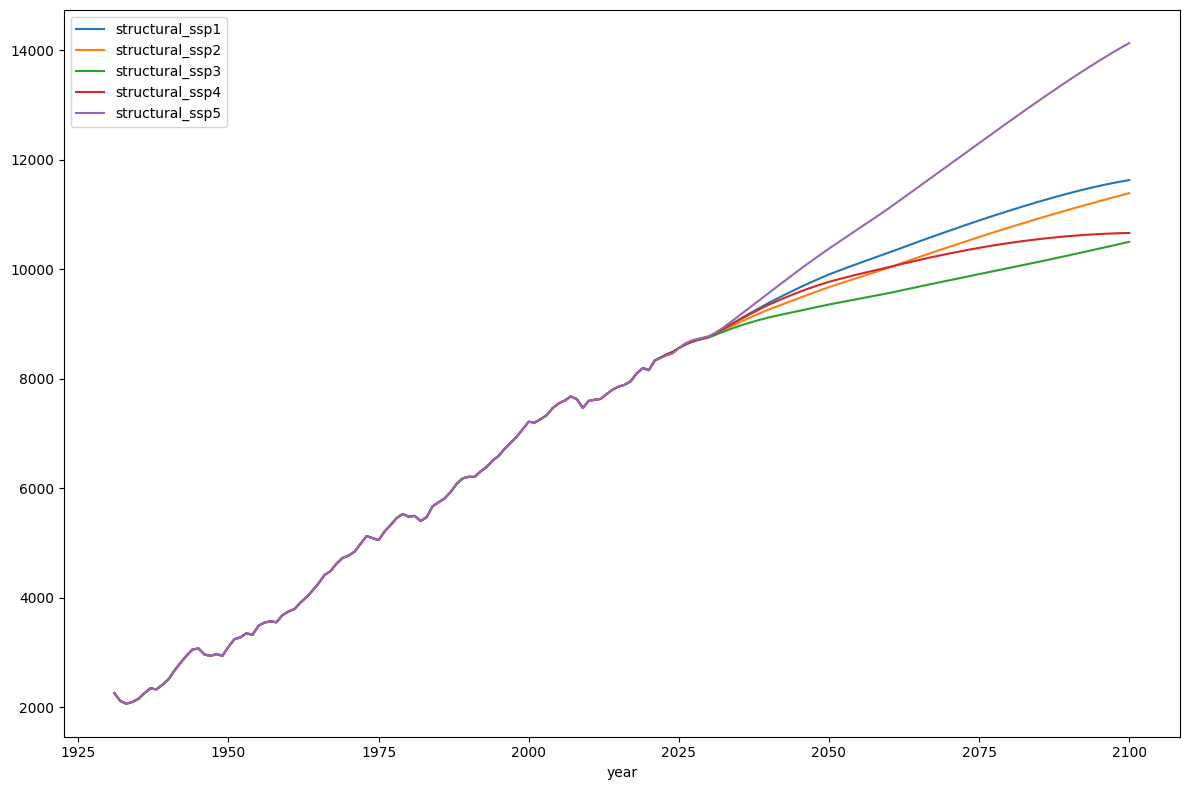

In [989]:
df_steel_forecast_9.plot()

## Method 10

In [990]:
def forecast_structural_steel_10(
    df_gdp,
    df_energy,
    structural_constant,
    gdp_elast,
    energy_elast,
    energy_col="energy",
    scenarios=range(1, 6),
    start_year=2024,
    end_year=2100,
    scale=1e5,
):
    df_gdp = df_gdp.copy()
    df_energy = df_energy.copy()
    df_gdp.index = df_gdp.index.astype(int)
    df_energy.index = df_energy.index.astype(int)

    forecast_years = np.arange(start_year, end_year + 1)

    energy_fore = df_energy.loc[forecast_years, energy_col]

    data = {}
    for s in scenarios:
        gdp_col = f"total_gdp_ssp{s}"

        gdp_fore = df_gdp.loc[forecast_years, gdp_col]

        steel_fore_vals = (
            structural_constant
            * (gdp_elast * np.log(gdp_fore))
            * (energy_fore ** energy_elast)
        )

        data[f"structural_ssp{s}"] = steel_fore_vals / scale

    df_steel_forecast = pd.DataFrame(data, index=forecast_years)
    df_steel_forecast.index.name = "year"

    return df_steel_forecast

In [991]:
df_steel_forecast_10 = forecast_structural_steel_10(
    df_gdp=df_total_gdp,
    df_energy=df_energy_use,
    structural_constant=stuctural_constant,  # your spelling
    gdp_elast=gdp_elast,
    energy_elast=energy_elast,
    energy_col='energy usage',
    scenarios=range(1, 6),      # SSP1–SSP5
    start_year=1931,
    end_year=2100,
    scale=1.1e-3
)

<Axes: xlabel='year'>

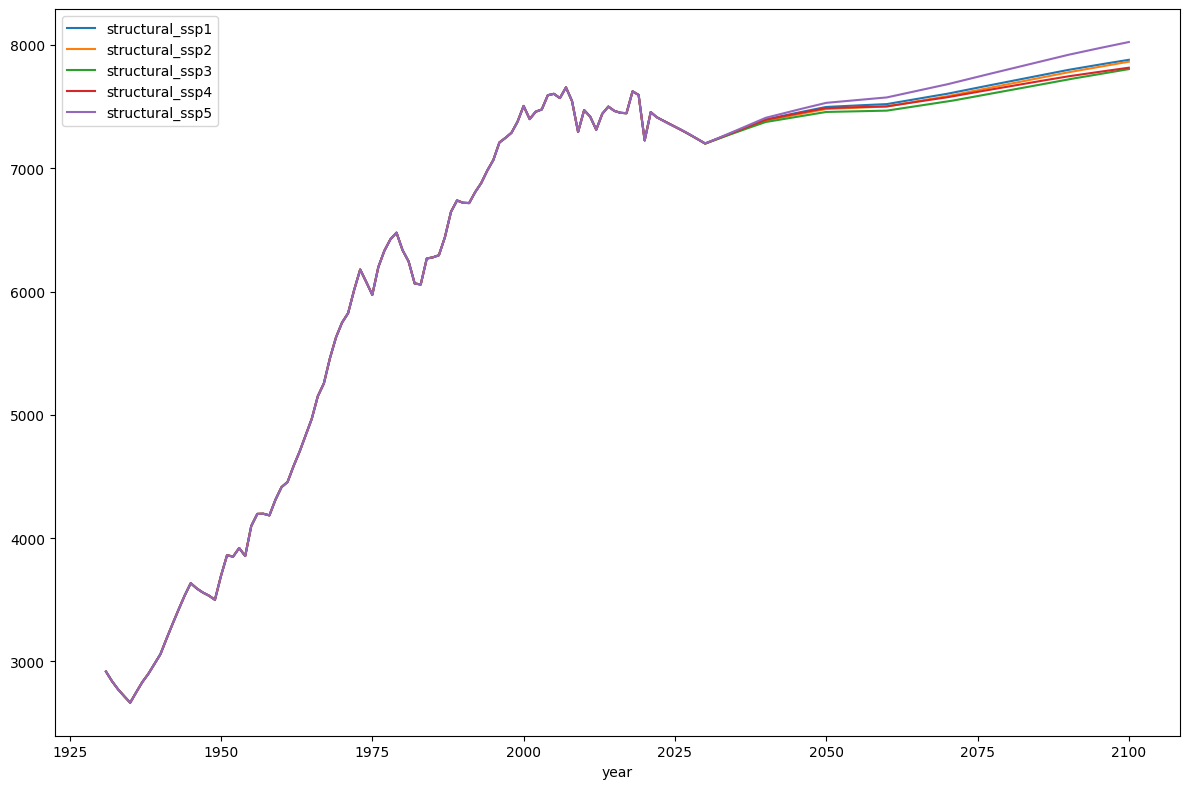

In [992]:
df_steel_forecast_10.plot()

## Quick Comparison

In [993]:
print(df_steel.iloc[91,1])
print(df_steel_forecast.iloc[91,1])
print(df_steel_forecast_1.iloc[91,1])
print(df_steel_forecast_2.iloc[91,1])
print(df_steel_forecast_3.iloc[91,1])
print(df_steel_forecast_4.iloc[91,1])
print(df_steel_forecast_5.iloc[91,1])
print(df_steel_forecast_6.iloc[91,1])
print(df_steel_forecast_7.iloc[91,1])
print(df_steel_forecast_8.iloc[91,1])
print(df_steel_forecast_9.iloc[91,1])
print(df_steel_forecast_10.iloc[91,1])

8267.62
6126.677148751376
9470.423296759323
6227.993082509649
7995.219832359811
8474.993718170366
8248.327724528255
8964.59748365432
10356.656969587757
6193.19867046223
8389.386577169897
7413.200485407692


In [994]:
def pct_diff_from_actual(reference, forecasts):
    return [(f - reference) / abs(reference) * 100 for f in forecasts]

reference = df_steel.iloc[91, 1]

forecasts = [
    df_steel_forecast.iloc[91, 1],
    df_steel_forecast_1.iloc[91, 1],
    df_steel_forecast_2.iloc[91, 1],
    df_steel_forecast_3.iloc[91, 1],
    df_steel_forecast_4.iloc[91, 1],
    df_steel_forecast_5.iloc[91, 1],
    df_steel_forecast_6.iloc[91, 1],
    df_steel_forecast_7.iloc[91, 1],
    df_steel_forecast_8.iloc[91, 1],
    df_steel_forecast_9.iloc[91, 1],
    df_steel_forecast_10.iloc[91, 1],
]

diffs = pct_diff_from_actual(reference, forecasts)
for i, d in enumerate(diffs):
    label = "df_steel_forecast" if i == 0 else f"df_steel_forecast_{i}"
    print(f"{label}: {d:+.2f}%")

df_steel_forecast: -25.90%
df_steel_forecast_1: +14.55%
df_steel_forecast_2: -24.67%
df_steel_forecast_3: -3.29%
df_steel_forecast_4: +2.51%
df_steel_forecast_5: -0.23%
df_steel_forecast_6: +8.43%
df_steel_forecast_7: +25.27%
df_steel_forecast_8: -25.09%
df_steel_forecast_9: +1.47%
df_steel_forecast_10: -10.33%


In [995]:
print(df_steel.iloc[0,1])
print(df_steel_forecast_1.iloc[0,1])
print(df_steel_forecast_2.iloc[0,1])
print(df_steel_forecast_3.iloc[0,1])
print(df_steel_forecast_4.iloc[0,1])
print(df_steel_forecast_5.iloc[0,1])
print(df_steel_forecast_6.iloc[0,1])
print(df_steel_forecast_7.iloc[0,1])
print(df_steel_forecast_8.iloc[0,1])
print(df_steel_forecast_9.iloc[0,1])
print(df_steel_forecast_10.iloc[0,1])

2396.48
648.7308561548161
3753.886433619778
762.7662473651103
1872.615081813654
3082.3504309831114
7727.690110046221
227.58652809971974
2092.4178991470903
2260.653652843109
2917.1954694777264


In [996]:
def pct_diff_from_actual(reference, forecasts):
    return [(f - reference) / abs(reference) * 100 for f in forecasts]

reference = df_steel.iloc[0, 1]

forecasts = [
    df_steel_forecast.iloc[0, 1],
    df_steel_forecast_1.iloc[0, 1],
    df_steel_forecast_2.iloc[0, 1],
    df_steel_forecast_3.iloc[0, 1],
    df_steel_forecast_4.iloc[0, 1],
    df_steel_forecast_5.iloc[0, 1],
    df_steel_forecast_6.iloc[0, 1],
    df_steel_forecast_7.iloc[0, 1],
    df_steel_forecast_8.iloc[0, 1],
    df_steel_forecast_9.iloc[0, 1],
    df_steel_forecast_10.iloc[0, 1],
]

diffs = pct_diff_from_actual(reference, forecasts)
for i, d in enumerate(diffs):
    label = "df_steel_forecast" if i == 0 else f"df_steel_forecast_{i}"
    print(f"{label}: {d:+.2f}%")

df_steel_forecast: -59.60%
df_steel_forecast_1: -72.93%
df_steel_forecast_2: +56.64%
df_steel_forecast_3: -68.17%
df_steel_forecast_4: -21.86%
df_steel_forecast_5: +28.62%
df_steel_forecast_6: +222.46%
df_steel_forecast_7: -90.50%
df_steel_forecast_8: -12.69%
df_steel_forecast_9: -5.67%
df_steel_forecast_10: +21.73%


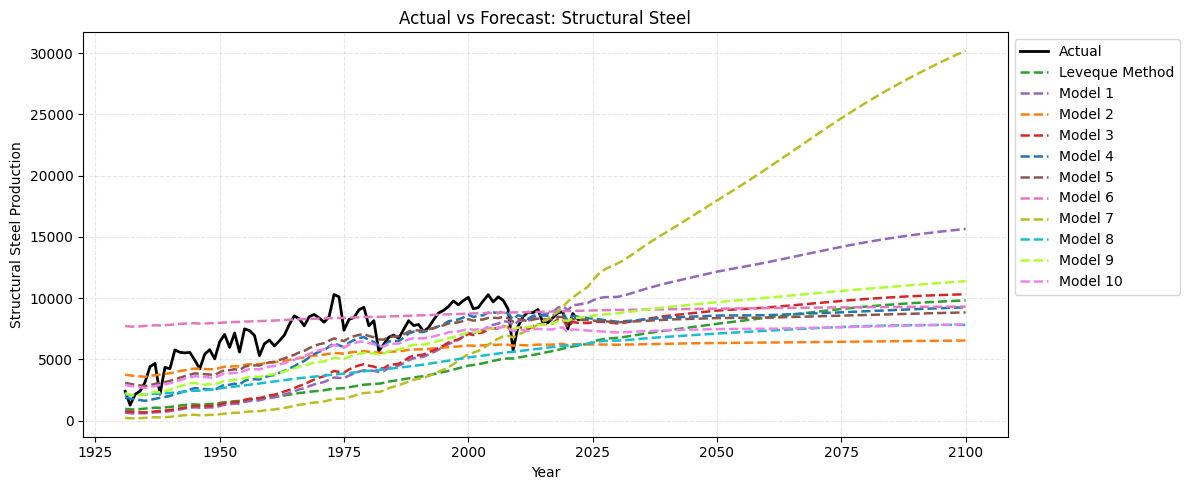

In [997]:
## Model Visual Comp

fig, ax = plt.subplots(figsize=(12, 5))

df_steel['structural-total'].plot(ax=ax, color='black', lw=2, label='Actual')
df_steel_forecast['structural_ssp2'].plot(ax=ax, color='tab:green', lw=1.8, linestyle='--', label='Leveque Method')
df_steel_forecast_1['structural_ssp2'].plot(ax=ax, color='tab:purple', lw=1.8, linestyle='--', label='Model 1')
df_steel_forecast_2['structural_ssp2'].plot(ax=ax, color='tab:orange', lw=1.8, linestyle='--', label='Model 2')
df_steel_forecast_3['structural_ssp2'].plot(ax=ax, color='tab:red', lw=1.8, linestyle='--', label='Model 3')
df_steel_forecast_4['structural_ssp2'].plot(ax=ax, color='tab:blue', lw=1.8, linestyle='--', label='Model 4')
df_steel_forecast_5['structural_ssp2'].plot(ax=ax, color='tab:brown', lw=1.8, linestyle='--', label='Model 5')
df_steel_forecast_6['structural_ssp2'].plot(ax=ax, color='tab:pink', lw=1.8, linestyle='--', label='Model 6')
df_steel_forecast_7['structural_ssp2'].plot(ax=ax, color='tab:olive', lw=1.8, linestyle='--', label='Model 7')
df_steel_forecast_8['structural_ssp2'].plot(ax=ax, color='tab:cyan', lw=1.8, linestyle='--', label='Model 8')
df_steel_forecast_9['structural_ssp2'].plot(ax=ax, color='greenyellow', lw=1.8, linestyle='--', label='Model 9')
df_steel_forecast_10['structural_ssp2'].plot(ax=ax, color='violet', lw=1.8, linestyle='--', label='Model 10')


ax.set_xlabel('Year')
ax.set_ylabel('Structural Steel Production')
ax.set_title('Actual vs Forecast: Structural Steel')
ax.legend(loc = 'upper left', bbox_to_anchor=(1,1))
ax.grid(True, linestyle='--', alpha=0.3)
plt.show()

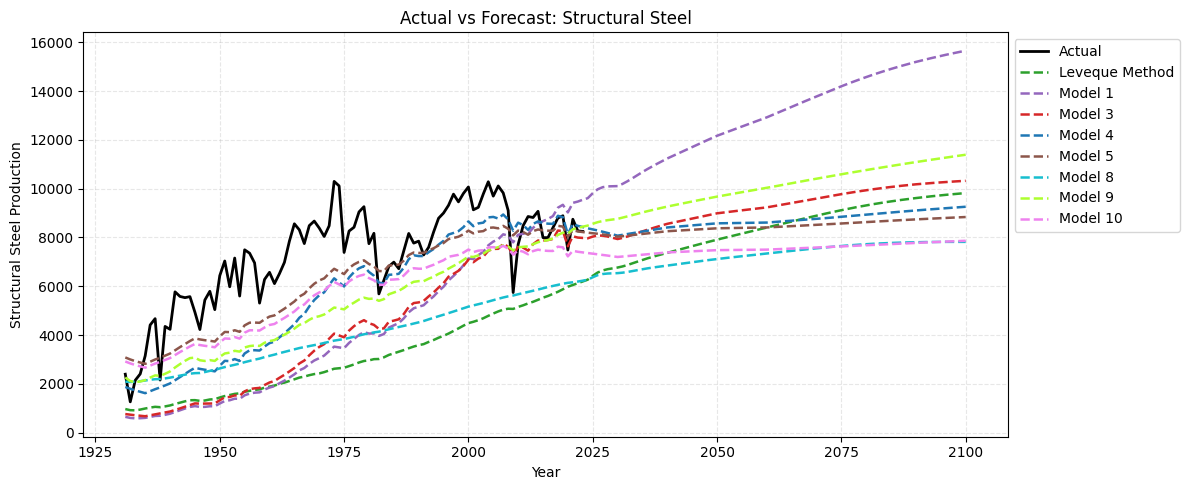

In [998]:
## Model Visual Comp

fig, ax = plt.subplots(figsize=(12, 5))

df_steel['structural-total'].plot(ax=ax, color='black', lw=2, label='Actual')
df_steel_forecast['structural_ssp2'].plot(ax=ax, color='tab:green', lw=1.8, linestyle='--', label='Leveque Method')
df_steel_forecast_1['structural_ssp2'].plot(ax=ax, color='tab:purple', lw=1.8, linestyle='--', label='Model 1')
#df_steel_forecast_2['structural_ssp2'].plot(ax=ax, color='tab:orange', lw=1.8, linestyle='--', label='Model 2')
df_steel_forecast_3['structural_ssp2'].plot(ax=ax, color='tab:red', lw=1.8, linestyle='--', label='Model 3')
df_steel_forecast_4['structural_ssp2'].plot(ax=ax, color='tab:blue', lw=1.8, linestyle='--', label='Model 4')
df_steel_forecast_5['structural_ssp2'].plot(ax=ax, color='tab:brown', lw=1.8, linestyle='--', label='Model 5')
#df_steel_forecast_6['structural_ssp2'].plot(ax=ax, color='tab:pink', lw=1.8, linestyle='--', label='Model 6')
#df_steel_forecast_7['structural_ssp2'].plot(ax=ax, color='tab:olive', lw=1.8, linestyle='--', label='Model 7')
df_steel_forecast_8['structural_ssp2'].plot(ax=ax, color='tab:cyan', lw=1.8, linestyle='--', label='Model 8')
df_steel_forecast_9['structural_ssp2'].plot(ax=ax, color='greenyellow', lw=1.8, linestyle='--', label='Model 9')
df_steel_forecast_10['structural_ssp2'].plot(ax=ax, color='violet', lw=1.8, linestyle='--', label='Model 10')


ax.set_xlabel('Year')
ax.set_ylabel('Structural Steel Production')
ax.set_title('Actual vs Forecast: Structural Steel')
ax.legend(loc = 'upper left', bbox_to_anchor=(1,1))
ax.grid(True, linestyle='--', alpha=0.3)
plt.show()

<Axes: >

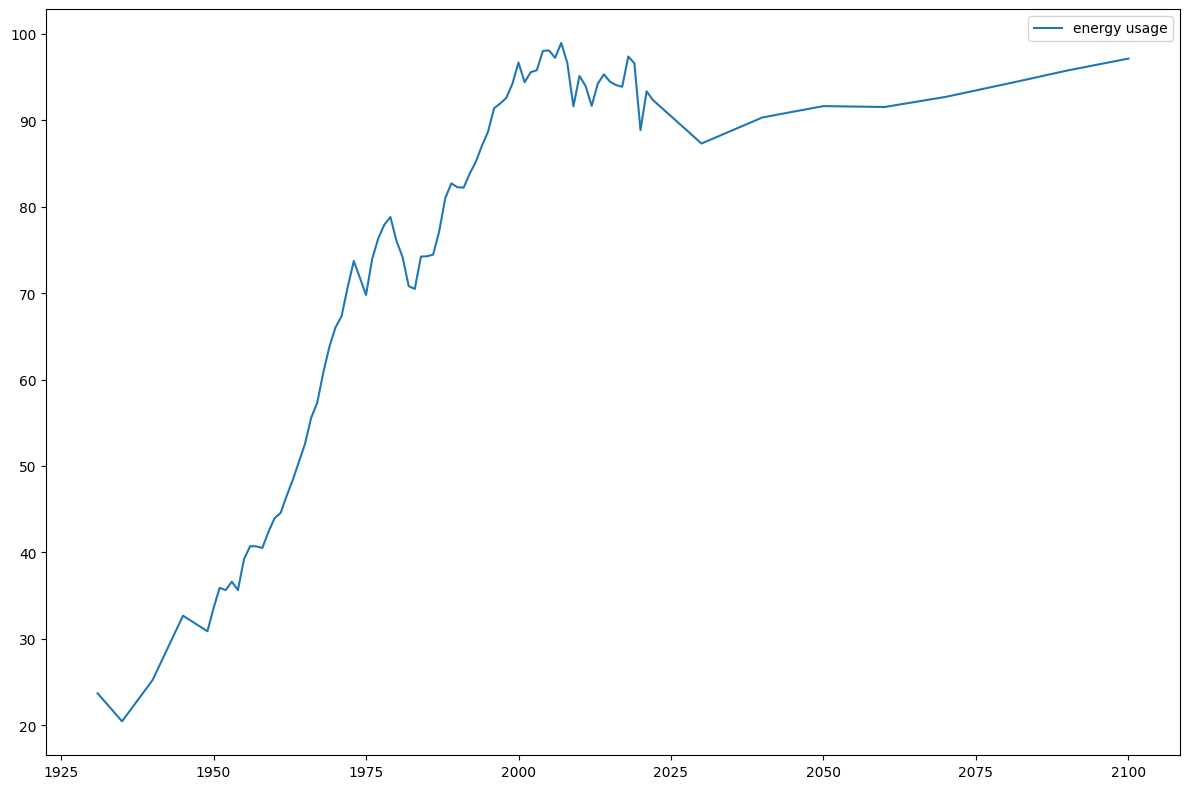

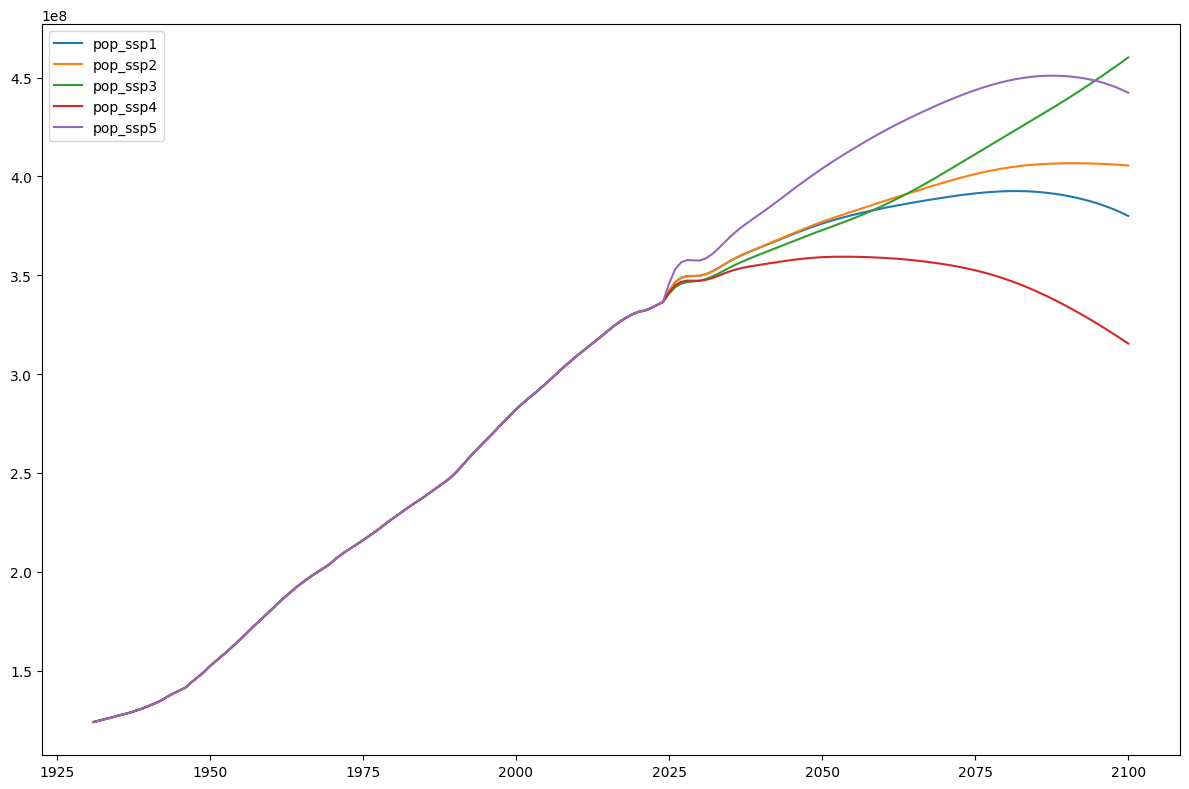

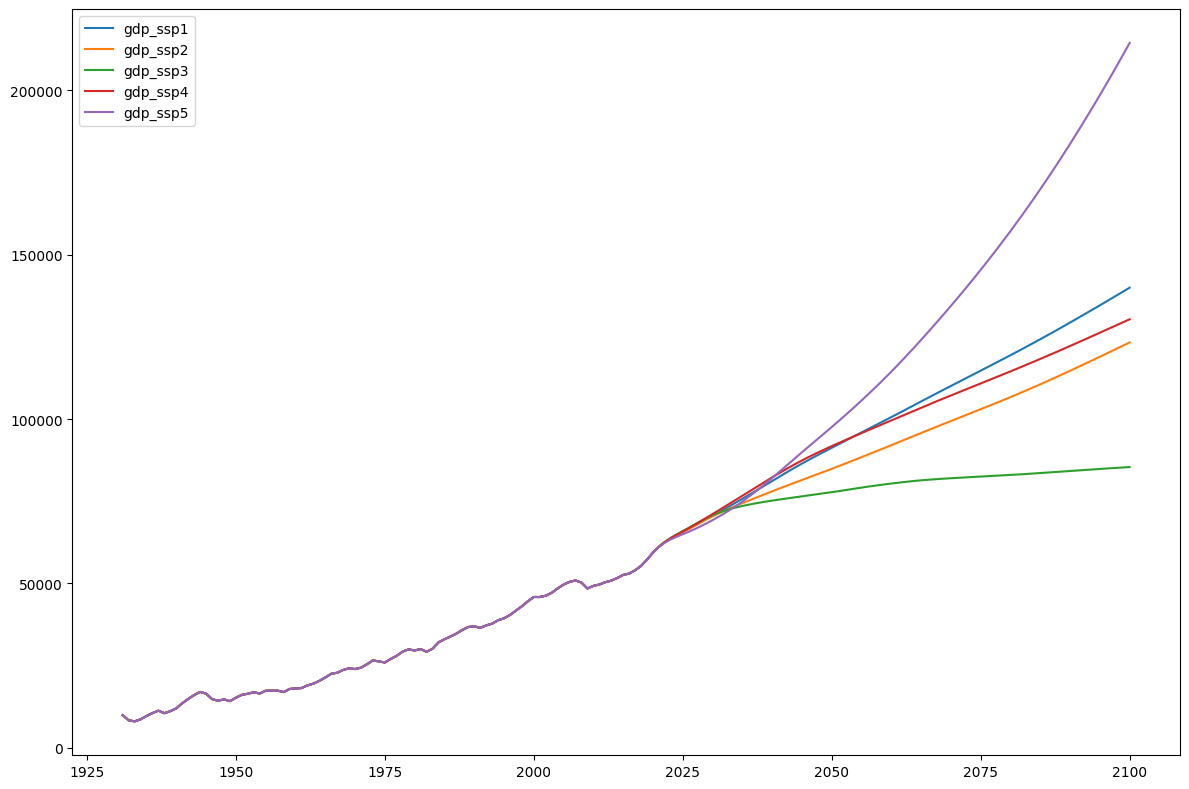

In [999]:
df_energy_use.plot()
df_population.plot()
df_gdp.plot()

## Statistical Evaluation

              R²       RMSE        MAE  MAPE (%)       Bias     NSE
Model                                                              
Leveque  -3.8302  4463.9829  4216.7890   58.8198 -4216.7890 -3.8302
Model 1  -2.3206  3701.2752  3273.8809   49.2554 -3059.6297 -2.3206
Model 3  -2.0097  3523.7514  3112.4179   46.7093 -3076.0554 -2.0097
Model 4  -0.1381  2166.8987  1752.3887   26.6773 -1603.8624 -0.1381
Model 5   0.3645  1619.2543  1358.4301   20.8386 -1138.1364  0.3645
Model 8  -2.0744  3561.4355  3301.1870   44.3536 -3282.7754 -2.0744
Model 9  -0.4718  2464.1543  2144.2617   30.1036 -2063.7844 -0.4718
Model 10  0.0319  1998.4828  1781.3041   25.7300 -1658.5824  0.0319


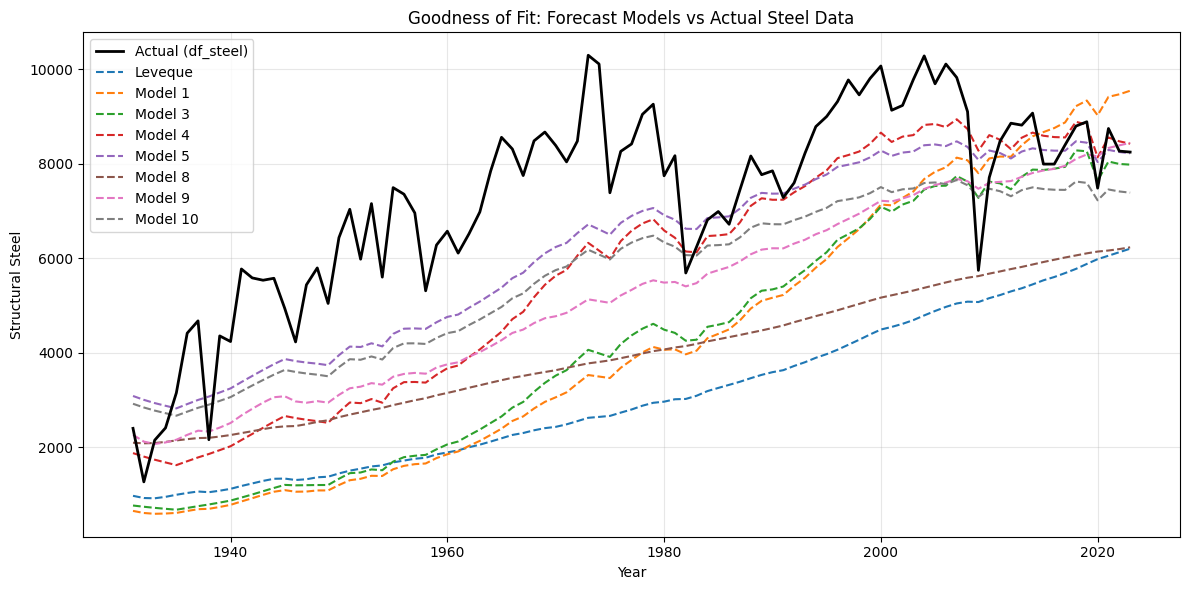

In [1000]:
def goodness_of_fit(df_actual, forecast_dict, col=1):
    """
    Evaluates goodness of fit for multiple forecast models against actual data.
    
    Parameters:
        df_actual: DataFrame with actual steel values
        forecast_dict: dict of {model_name: forecast_dataframe}
        col: column index to evaluate (default 1)
    """
    # Align on shared index
    actual_full = df_actual.iloc[:, col]
    
    results = []
    aligned_forecasts = {}

    for name, df_fore in forecast_dict.items():
        fore_series = df_fore.iloc[:, col]
        shared_idx = actual_full.index.intersection(fore_series.index)
        
        actual = actual_full.loc[shared_idx].values
        predicted = fore_series.loc[shared_idx].values

        r2 = r2_score(actual, predicted)
        rmse = np.sqrt(mean_squared_error(actual, predicted))
        mae = mean_absolute_error(actual, predicted)
        mape = np.mean(np.abs((actual - predicted) / np.abs(actual))) * 100
        bias = np.mean(predicted - actual)
        nse = 1 - (np.sum((actual - predicted) ** 2) / np.sum((actual - np.mean(actual)) ** 2))

        results.append({
            "Model": name,
            "R²": round(r2, 4),
            "RMSE": round(rmse, 4),
            "MAE": round(mae, 4),
            "MAPE (%)": round(mape, 4),
            "Bias": round(bias, 4),
            "NSE": round(nse, 4),
        })
        aligned_forecasts[name] = (shared_idx, predicted, actual)

    df_results = pd.DataFrame(results).set_index("Model")
    print(df_results.to_string())

    # --- Plot ---
    fig, ax = plt.subplots(figsize=(12, 6))

    # Plot actual once (use first model's shared index)
    first_name = list(aligned_forecasts.keys())[0]
    first_idx, _, first_actual = aligned_forecasts[first_name]
    ax.plot(first_idx, first_actual, color="black", linewidth=2, label="Actual (df_steel)", zorder=5)

    for name, (idx, predicted, _) in aligned_forecasts.items():
        ax.plot(idx, predicted, linewidth=1.5, linestyle="--", label=name)

    ax.set_title("Goodness of Fit: Forecast Models vs Actual Steel Data")
    ax.set_xlabel("Year")
    ax.set_ylabel("Structural Steel")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    return df_results


# --- Run it ---
forecast_dict = {
    "Leveque":  df_steel_forecast,
    "Model 1":  df_steel_forecast_1,
    "Model 3":  df_steel_forecast_3,
    "Model 4":  df_steel_forecast_4,
    "Model 5":  df_steel_forecast_5,
    "Model 8":  df_steel_forecast_8,
    "Model 9":  df_steel_forecast_9,
    "Model 10": df_steel_forecast_10,
}

df_gof = goodness_of_fit(df_steel, forecast_dict, col=1)

          R² (linear)  R² (quadratic)       RMSE        MAE  MAPE (%)       Bias     NSE
Model                                                                                   
Leveque       -3.8302         -5.0956  4463.9829  4216.7890   58.8198 -4216.7890 -3.8302
Model 1       -2.3206         -3.1403  3701.2752  3273.8809   49.2554 -3059.6297 -2.3206
Model 3       -2.0097         -2.7271  3523.7514  3112.4179   46.7093 -3076.0554 -2.0097
Model 4       -0.1381         -0.2558  2166.8987  1752.3887   26.6773 -1603.8624 -0.1381
Model 5        0.3645          0.4340  1619.2543  1358.4301   20.8386 -1138.1364  0.3645
Model 8       -2.0744         -2.7560  3561.4355  3301.1870   44.3536 -3282.7754 -2.0744
Model 9       -0.4718         -0.6652  2464.1543  2144.2617   30.1036 -2063.7844 -0.4718
Model 10       0.0319         -0.0025  1998.4828  1781.3041   25.7300 -1658.5824  0.0319


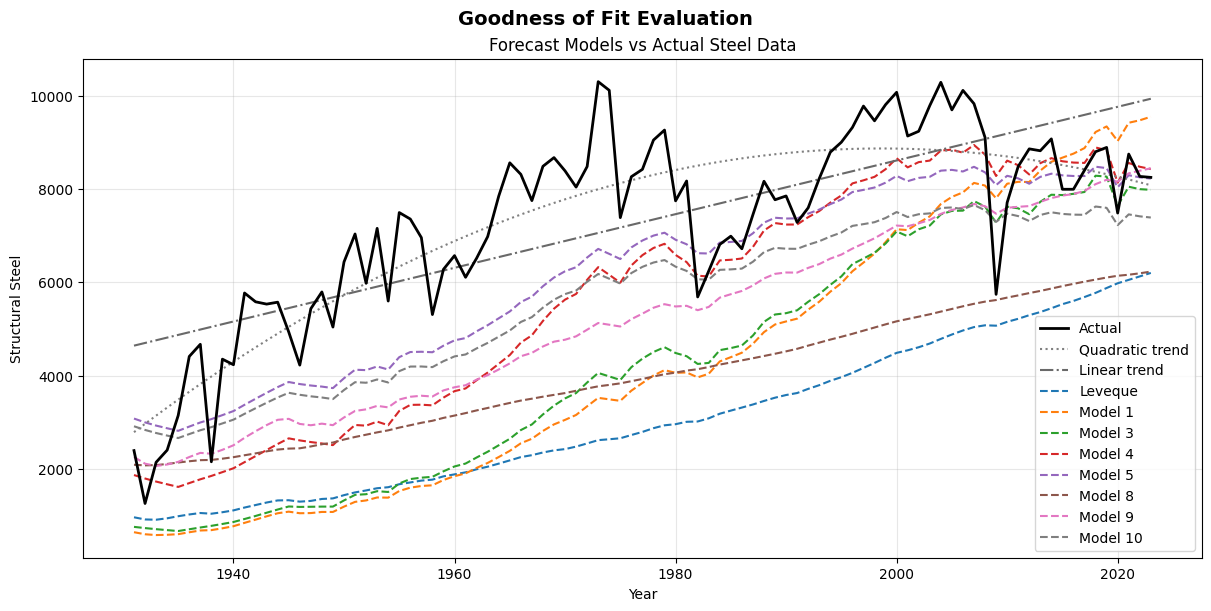

In [1001]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from scipy import stats
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

def goodness_of_fit(df_actual, forecast_dict, col=1):
    actual_full = df_actual.iloc[:, col]
    
    results = []
    aligned_forecasts = {}

    for name, df_fore in forecast_dict.items():
        fore_series = df_fore.iloc[:, col]
        shared_idx = actual_full.index.intersection(fore_series.index)
        
        actual = actual_full.loc[shared_idx].values
        predicted = fore_series.loc[shared_idx].values
        years = shared_idx.values.astype(float)

        r2_linear = r2_score(actual, predicted)

        coeffs = np.polyfit(years, actual, 2)
        actual_quad = np.polyval(coeffs, years)
        r2_quad = r2_score(actual_quad, predicted)

        rmse = np.sqrt(mean_squared_error(actual, predicted))
        mae = mean_absolute_error(actual, predicted)
        mape = np.mean(np.abs((actual - predicted) / np.abs(actual))) * 100
        bias = np.mean(predicted - actual)
        nse = 1 - (np.sum((actual - predicted) ** 2) / np.sum((actual - np.mean(actual)) ** 2))

        results.append({
            "Model": name,
            "R² (linear)": round(r2_linear, 4),
            "R² (quadratic)": round(r2_quad, 4),
            "RMSE": round(rmse, 4),
            "MAE": round(mae, 4),
            "MAPE (%)": round(mape, 4),
            "Bias": round(bias, 4),
            "NSE": round(nse, 4),
        })
        aligned_forecasts[name] = (shared_idx, predicted, actual, actual_quad)

    df_results = pd.DataFrame(results).set_index("Model")
    print(df_results.to_string())

    # --- Plot ---
    fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)

    first_name = list(aligned_forecasts.keys())[0]
    first_idx, _, first_actual, first_quad = aligned_forecasts[first_name]
    years_float = first_idx.values.astype(float)

    # Linear trend of actual
    lin_coeffs = np.polyfit(years_float, first_actual, 1)
    actual_linear = np.polyval(lin_coeffs, years_float)

    ax.plot(first_idx, first_actual, color="black", linewidth=2, label="Actual", zorder=5)
    ax.plot(first_idx, first_quad, color="gray", linewidth=1.5, linestyle=":", label="Quadratic trend", zorder=4)
    ax.plot(first_idx, actual_linear, color="dimgray", linewidth=1.5, linestyle="-.", label="Linear trend", zorder=4)

    for name, (idx, predicted, _, _) in aligned_forecasts.items():
        ax.plot(idx, predicted, linewidth=1.5, linestyle="--", label=name)

    ax.set_title("Forecast Models vs Actual Steel Data")
    ax.set_xlabel("Year")
    ax.set_ylabel("Structural Steel")
    ax.legend()
    ax.grid(True, alpha=0.3)

    plt.suptitle("Goodness of Fit Evaluation", fontsize=14, fontweight="bold")
    plt.show()

    return df_results


# --- Run it ---
forecast_dict = {
    "Leveque":  df_steel_forecast,
    "Model 1":  df_steel_forecast_1,
    "Model 3":  df_steel_forecast_3,
    "Model 4":  df_steel_forecast_4,
    "Model 5":  df_steel_forecast_5,
    "Model 8":  df_steel_forecast_8,
    "Model 9":  df_steel_forecast_9,
    "Model 10": df_steel_forecast_10,
}

df_gof = goodness_of_fit(df_steel, forecast_dict, col=1)

<Axes: >

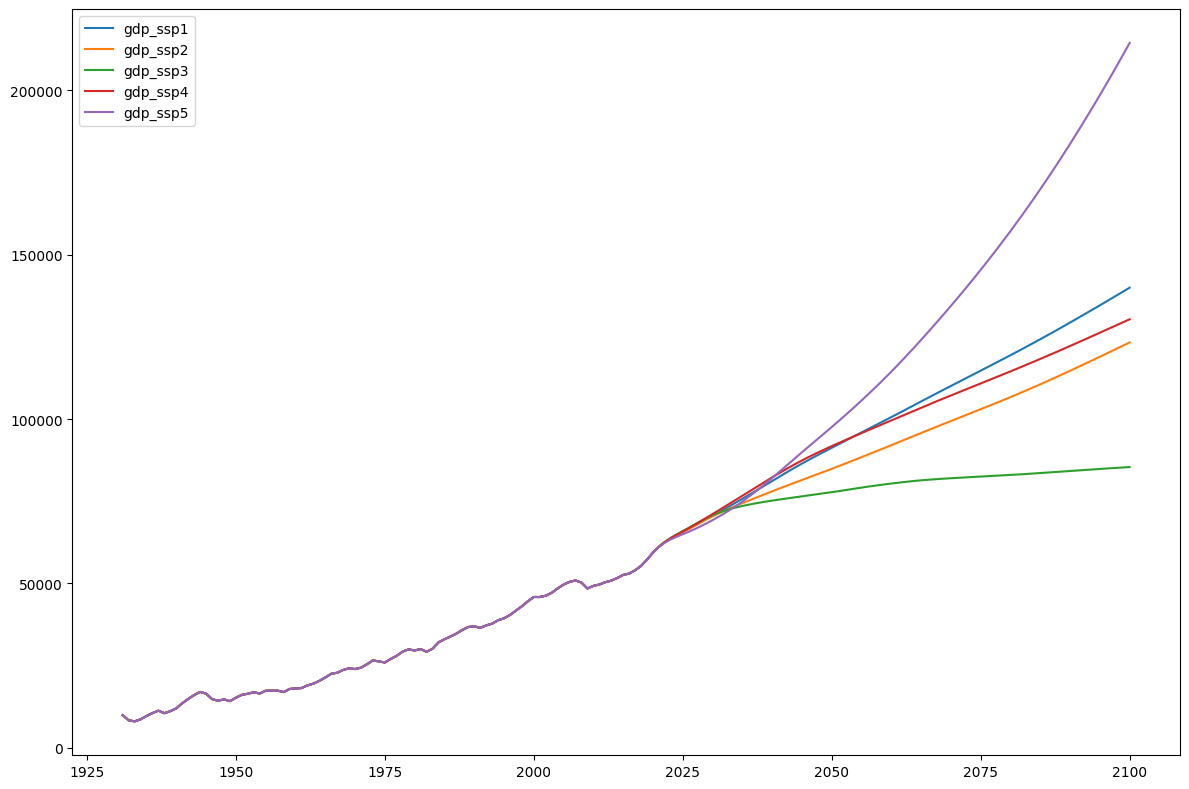

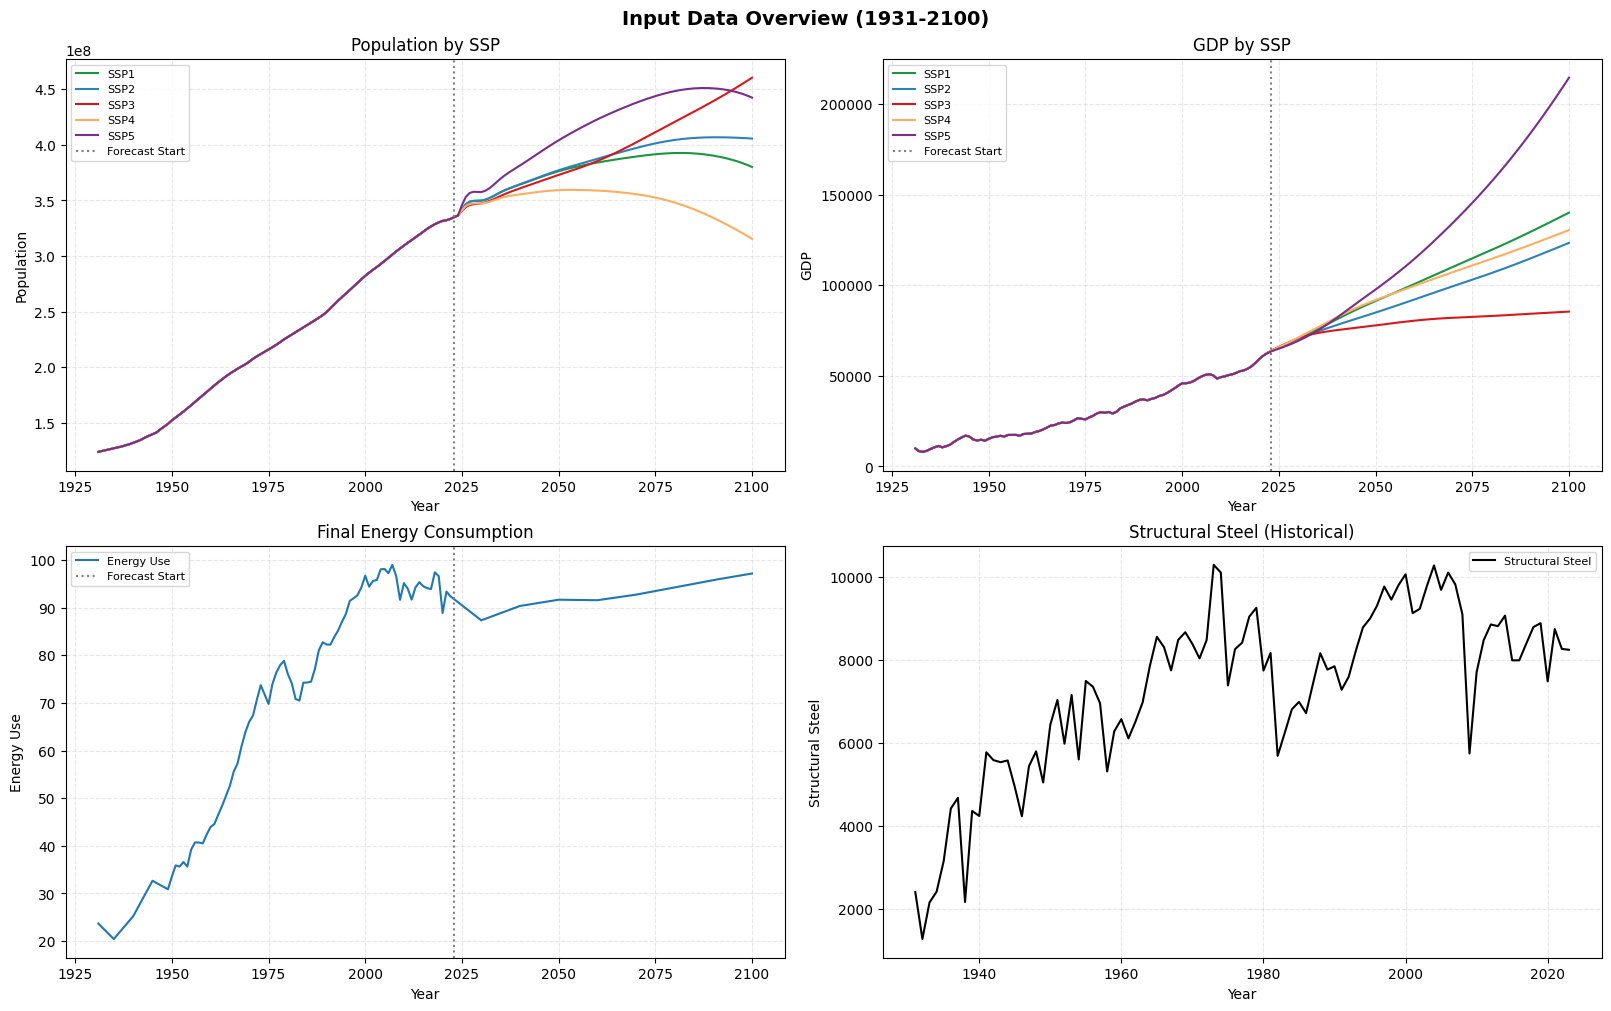

: 

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10), constrained_layout=True)

ssp_colors = {
    'ssp1': '#1a9641',
    'ssp2': '#2b83ba',
    'ssp3': '#d7191c',
    'ssp4': '#fdae61',
    'ssp5': '#7b2d8b',
}

# ── Top Left: Population ──────────────────────────────────────────────────────
ax = axes[0, 0]
for ssp, color in ssp_colors.items():
    col = f'pop_{ssp}'
    ax.plot(df_population.index, df_population[col],
            color=color, lw=1.5, label=ssp.upper())
ax.axvline(2023, color='grey', linestyle=':', lw=1.5, label='Forecast Start')
ax.set_title('Population by SSP')
ax.set_xlabel('Year')
ax.set_ylabel('Population')
ax.legend(fontsize=8)
ax.grid(True, linestyle='--', alpha=0.3)

# ── Top Right: GDP ────────────────────────────────────────────────────────────
ax = axes[0, 1]
for ssp, color in ssp_colors.items():
    col = f'gdp_{ssp}'
    ax.plot(df_gdp.index, df_gdp[col],
            color=color, lw=1.5, label=ssp.upper())
ax.axvline(2023, color='grey', linestyle=':', lw=1.5, label='Forecast Start')
ax.set_title('GDP by SSP')
ax.set_xlabel('Year')
ax.set_ylabel('GDP')
ax.legend(fontsize=8)
ax.grid(True, linestyle='--', alpha=0.3)

# ── Bottom Left: Energy Use ───────────────────────────────────────────────────
ax = axes[1, 0]
ax.plot(df_energy_use.index, df_energy_use['energy usage'],
        color='tab:blue', lw=1.5, label='Energy Use')
ax.axvline(2023, color='grey', linestyle=':', lw=1.5, label='Forecast Start')
ax.set_title('Final Energy Consumption')
ax.set_xlabel('Year')
ax.set_ylabel('Energy Use')
ax.legend(fontsize=8)
ax.grid(True, linestyle='--', alpha=0.3)

# ── Bottom Right: Steel ───────────────────────────────────────────────────────
ax = axes[1, 1]
ax.plot(df_steel.index, df_steel['structural-total'],
        color='black', lw=1.5, label='Structural Steel')
ax.set_title('Structural Steel (Historical)')
ax.set_xlabel('Year')
ax.set_ylabel('Structural Steel')
ax.legend(fontsize=8)
ax.grid(True, linestyle='--', alpha=0.3)

fig.suptitle('Input Data Overview (1931-2100)', fontsize=14, fontweight='bold')
plt.show()